# Visualização de Resultados Modal - Regressão Linear (r²)

Notebook para gerar plots dos resultados da análise de regressão linear (experimento 03), espelhando a estrutura do notebook PREDEP para comparação direta.

In [1]:
import sys
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.gridspec import GridSpec

sys.path.insert(0, str(Path.cwd().parent))

## 1. Funções de Plot

In [2]:
def plot_4x4_optimal_lags_r2(ds, mov_index, output_dir, seasons):
    """Plot 4x4: r² máximo + 3 maiores lags por estação."""
    valid_seasons = []
    for season_idx, season in enumerate(seasons):
        r2_data = ds['regression_r2'].isel(mov=0, season=season_idx)
        if not np.all(np.isnan(r2_data.values)):
            valid_seasons.append((season_idx, season))

    if not valid_seasons:
        print("   Nenhuma estação com dados válidos")
        return None

    n_cols = len(valid_seasons)
    fig = plt.figure(figsize=(5 * n_cols, 22))
    gs = GridSpec(4, n_cols + 1, figure=fig,
                  width_ratios=[1] * n_cols + [0.05],
                  hspace=0.25, wspace=0.15,
                  left=0.05, right=0.95, top=0.94, bottom=0.05)
    plt.rcParams['text.usetex'] = False

    levels_r2 = np.arange(0.0, 1.1, 0.1)
    norm_r2 = BoundaryNorm(levels_r2, ncolors=plt.cm.jet.N, clip=True)
    lag_boundaries = np.arange(-0.5, 13.5, 1.0)
    lag_norm = BoundaryNorm(lag_boundaries, ncolors=plt.cm.jet.N, clip=True)

    im_r2 = im_lag = None

    for col_idx, (season_idx, season) in enumerate(valid_seasons):
        r2_values = ds['regression_r2'].isel(mov=0, season=season_idx).values

        sorted_indices = np.argsort(np.nan_to_num(r2_values, nan=-999), axis=0)
        lag_1st = sorted_indices[-1, :, :]
        lag_2nd = sorted_indices[-2, :, :]
        lag_3rd = sorted_indices[-3, :, :]

        lat_idx, lon_idx = np.meshgrid(
            np.arange(r2_values.shape[1]),
            np.arange(r2_values.shape[2]),
            indexing='ij'
        )
        r2_max = r2_values[lag_1st, lat_idx, lon_idx]

        all_nan = np.all(np.isnan(r2_values), axis=0)
        r2_max  = np.where(all_nan, np.nan, r2_max)
        lag_1st = np.where(all_nan, np.nan, lag_1st.astype(float))
        lag_2nd = np.where(all_nan, np.nan, lag_2nd.astype(float))
        lag_3rd = np.where(all_nan, np.nan, lag_3rd.astype(float))

        ax1 = fig.add_subplot(gs[0, col_idx])
        im1 = ax1.imshow(r2_max, cmap='jet', norm=norm_r2,
                         aspect='auto', origin='lower', interpolation='nearest')
        ax1.set_title(f'{season} - $r^2$ máximo', fontsize=12, fontweight='bold')
        ax1.axis('off')
        if im_r2 is None:
            im_r2 = im1

        ax2 = fig.add_subplot(gs[1, col_idx])
        im2 = ax2.imshow(lag_1st, cmap='jet', norm=lag_norm,
                         aspect='auto', origin='lower', interpolation='nearest')
        ax2.set_title(f'{season} - Lag $1^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax2.axis('off')
        if im_lag is None:
            im_lag = im2

        ax3 = fig.add_subplot(gs[2, col_idx])
        ax3.imshow(lag_2nd, cmap='jet', norm=lag_norm,
                   aspect='auto', origin='lower', interpolation='nearest')
        ax3.set_title(f'{season} - Lag $2^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax3.axis('off')

        ax4 = fig.add_subplot(gs[3, col_idx])
        ax4.imshow(lag_3rd, cmap='jet', norm=lag_norm,
                   aspect='auto', origin='lower', interpolation='nearest')
        ax4.set_title(f'{season} - Lag $3^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax4.axis('off')

    cbar_ax1 = fig.add_subplot(gs[0, n_cols])
    cbar1 = fig.colorbar(im_r2, cax=cbar_ax1, ticks=np.arange(0.0, 1.1, 0.1))
    cbar1.set_label('$r^2$', fontsize=12, fontweight='bold')

    cbar_ax2 = fig.add_subplot(gs[1:4, n_cols])
    cbar2 = fig.colorbar(im_lag, cax=cbar_ax2, ticks=list(range(13)))
    cbar2.set_label('Lag (meses)', fontsize=12, fontweight='bold')

    plt.suptitle(
        f'Lags Ótimos por Estação (Regressão Linear): {mov_index}\n'
        f'Linha 1: $r^2$ máximo | Linhas 2-4: Lags do $1^{{\\circ}}$,'
        f' $2^{{\\circ}}$ e $3^{{\\circ}}$ maiores $r^2$',
        fontsize=18, fontweight='bold'
    )

    output_file = output_dir / f"optimal_lag_seasons_{mov_index}_regression.png"
    plt.savefig(output_file, dpi=200, bbox_inches='tight')
    plt.close()
    return output_file


def plot_12x4_all_lags_r2(ds, mov_index, output_dir, seasons):
    """Plot 12x4: todos os lags por estação."""
    valid_seasons = []
    for season_idx, season in enumerate(seasons):
        r2_data = ds['regression_r2'].isel(mov=0, season=season_idx)
        if not np.all(np.isnan(r2_data.values)):
            valid_seasons.append((season_idx, season))

    if not valid_seasons:
        print("   Nenhuma estação com dados válidos")
        return None

    n_cols = len(valid_seasons)
    fig = plt.figure(figsize=(3 * n_cols, 30))
    gs = GridSpec(13, n_cols + 1, figure=fig,
                  width_ratios=[1] * n_cols + [0.05],
                  hspace=0.05, wspace=0.05,
                  left=0.08, right=0.95, top=0.96, bottom=0.02)
    plt.rcParams['text.usetex'] = False

    levels = np.arange(0.0, 1.1, 0.1)
    cmap = plt.cm.jet
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)

    n_lags = ds.dims['lag']
    im = None
    for lag in range(n_lags):
        for col_idx, (season_idx, season) in enumerate(valid_seasons):
            ax = fig.add_subplot(gs[lag, col_idx])
            data = ds['regression_r2'].isel(
                mov=0, season=season_idx, lag=lag
            ).values
            im = ax.imshow(data, cmap=cmap, norm=norm,
                           aspect='auto', origin='lower', interpolation='nearest')
            ax.axis('off')
            if lag == 0:
                ax.set_title(season, fontsize=11, fontweight='bold', pad=3)
            if col_idx == 0:
                ax.text(-0.15, 0.5, f'Lag {lag}',
                        transform=ax.transAxes,
                        rotation=90, va='center', ha='center',
                        fontsize=10, fontweight='bold')

    cbar_ax = fig.add_subplot(gs[:, n_cols])
    cbar = fig.colorbar(im, cax=cbar_ax, ticks=levels)
    cbar.set_label(
        '$r^2$ (Regressão Linear)\n0=Sem relação, 1=Relação perfeita',
        fontsize=11, fontweight='bold'
    )

    plt.suptitle(
        f'Regressão Linear $r^2$: {mov_index}\n'
        f'Linhas = Lags (0-11 meses) | Colunas = Estações',
        fontsize=14, fontweight='bold', y=0.99
    )

    output_file = output_dir / f"regression_12x4_grid_{mov_index}.png"
    plt.savefig(output_file, dpi=200, bbox_inches='tight')
    plt.close()
    return output_file


print("Funções de plot carregadas.")

Funções de plot carregadas.


## 2. Processar Todos os Índices

Índices disponíveis: 23
  AAO: 5 arquivo(s) .nc
  AMO: 4 arquivo(s) .nc
  AO: 4 arquivo(s) .nc
  EPNP: 4 arquivo(s) .nc
  IASAS: 4 arquivo(s) .nc
  ITSMRG2: 0 arquivo(s) .nc
  MEI: 4 arquivo(s) .nc
  NAO: 4 arquivo(s) .nc
  NIN03: 4 arquivo(s) .nc
  NIN034: 4 arquivo(s) .nc
  NIN04: 4 arquivo(s) .nc
  NIN12: 3 arquivo(s) .nc
  ONI: 4 arquivo(s) .nc
  PDO: 4 arquivo(s) .nc
  PNA: 4 arquivo(s) .nc
  QBO: 3 arquivo(s) .nc
  SAODI: 4 arquivo(s) .nc
  SASDI: 4 arquivo(s) .nc
  SIOD: 4 arquivo(s) .nc
  SOI: 4 arquivo(s) .nc
  TNA: 4 arquivo(s) .nc
  TSA: 3 arquivo(s) .nc
  WP: 4 arquivo(s) .nc


Processando: AAO
  DJF: OK — AAO/AAO/AAO_DJF_regression_brazil.nc
  MAM: OK — AAO/AAO/AAO_MAM_regression_brazil.nc
  JJA: OK — AAO/AAO/AAO_JJA_regression_brazil.nc
  SON: OK — AAO/AAO/AAO_SON_regression_brazil.nc

Gerando plots -> ../results/regression/AAO/plots/
  4x4:  optimal_lag_seasons_AAO_regression.png


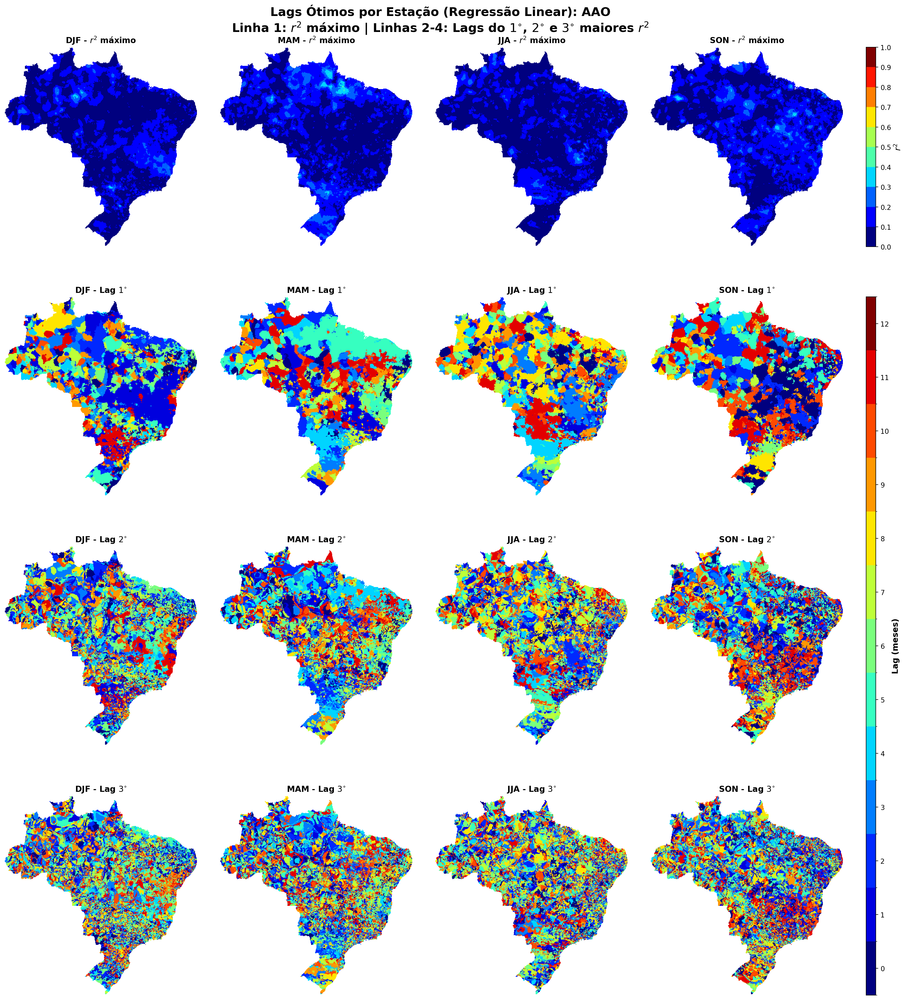

  12x4: regression_12x4_grid_AAO.png


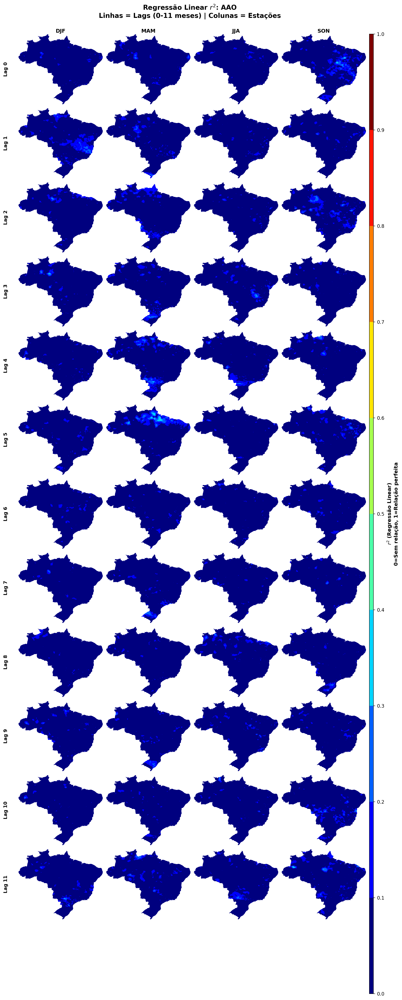


Processando: AMO
  DJF: OK — AMO/AMO/AMO_DJF_regression_brazil.nc
  MAM: OK — AMO/AMO/AMO_MAM_regression_brazil.nc
  JJA: OK — AMO/AMO/AMO_JJA_regression_brazil.nc
  SON: OK — AMO/AMO/AMO_SON_regression_brazil.nc

Gerando plots -> ../results/regression/AMO/plots/
  4x4:  optimal_lag_seasons_AMO_regression.png


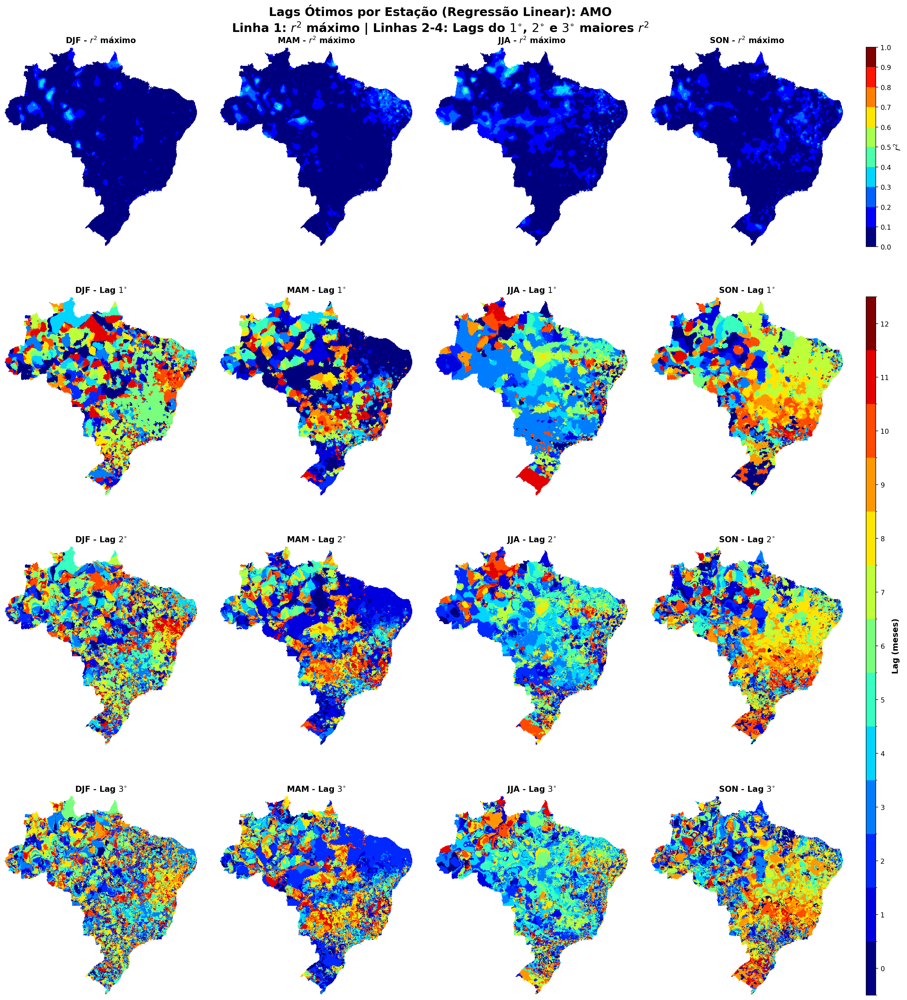

  12x4: regression_12x4_grid_AMO.png


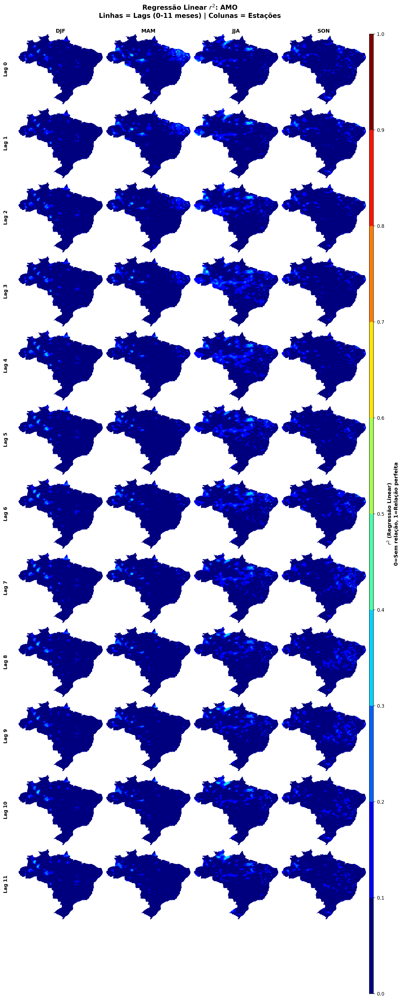


Processando: AO
  DJF: OK — AO/AO/AO_DJF_regression_brazil.nc
  MAM: OK — AO/AO/AO_MAM_regression_brazil.nc
  JJA: OK — AO/AO/AO_JJA_regression_brazil.nc
  SON: OK — AO/AO/AO_SON_regression_brazil.nc

Gerando plots -> ../results/regression/AO/plots/
  4x4:  optimal_lag_seasons_AO_regression.png


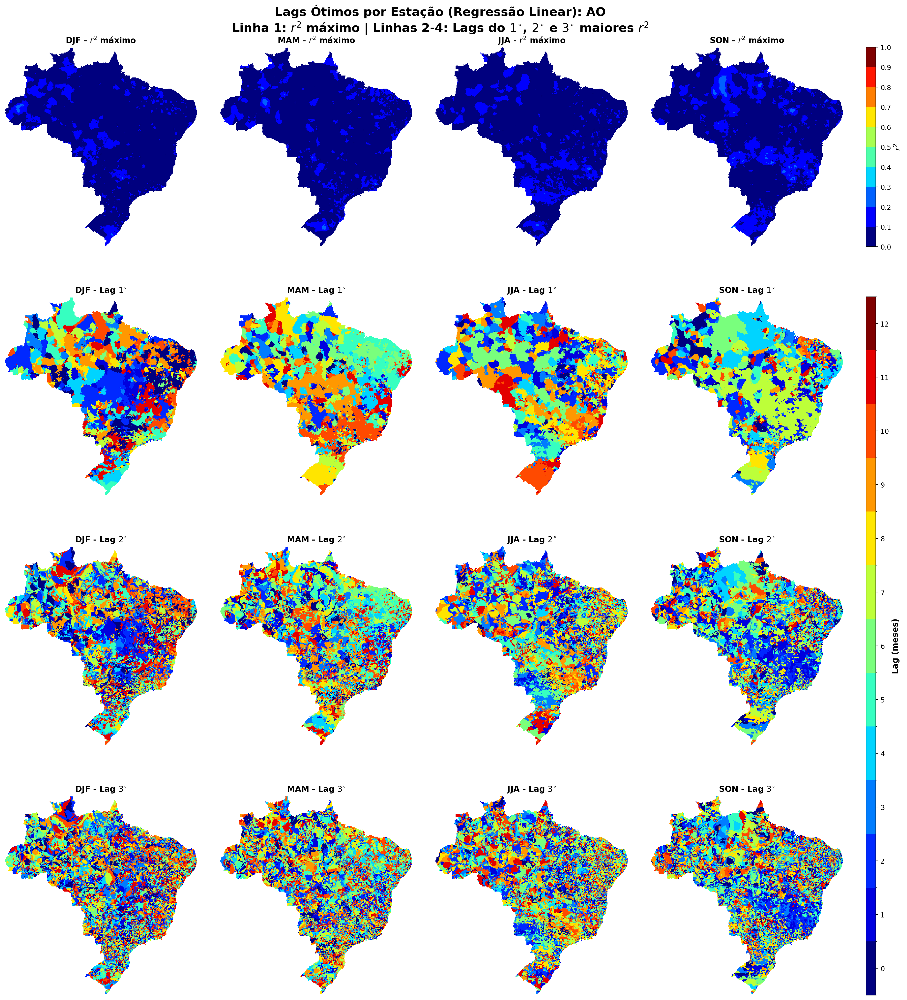

  12x4: regression_12x4_grid_AO.png


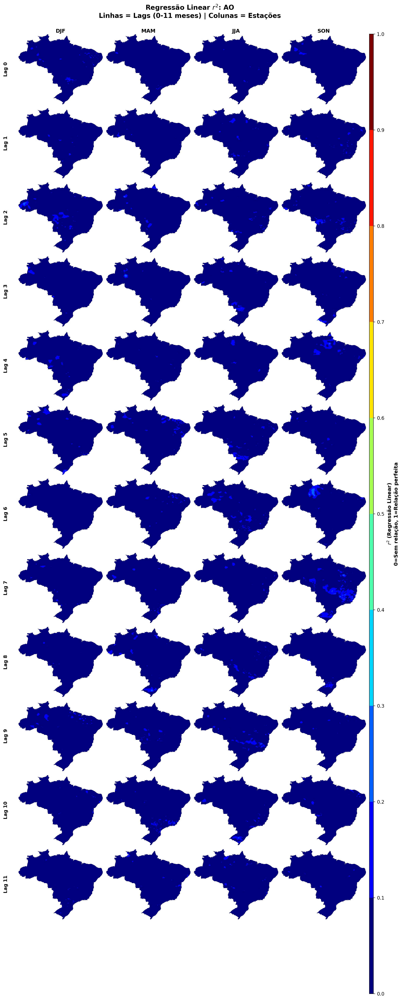


Processando: EPNP
  DJF: OK — EPNP/EPNP/EPNP_DJF_regression_brazil.nc
  MAM: OK — EPNP/EPNP/EPNP_MAM_regression_brazil.nc
  JJA: OK — EPNP/EPNP/EPNP_JJA_regression_brazil.nc
  SON: OK — EPNP/EPNP/EPNP_SON_regression_brazil.nc

Gerando plots -> ../results/regression/EPNP/plots/
  4x4:  optimal_lag_seasons_EPNP_regression.png


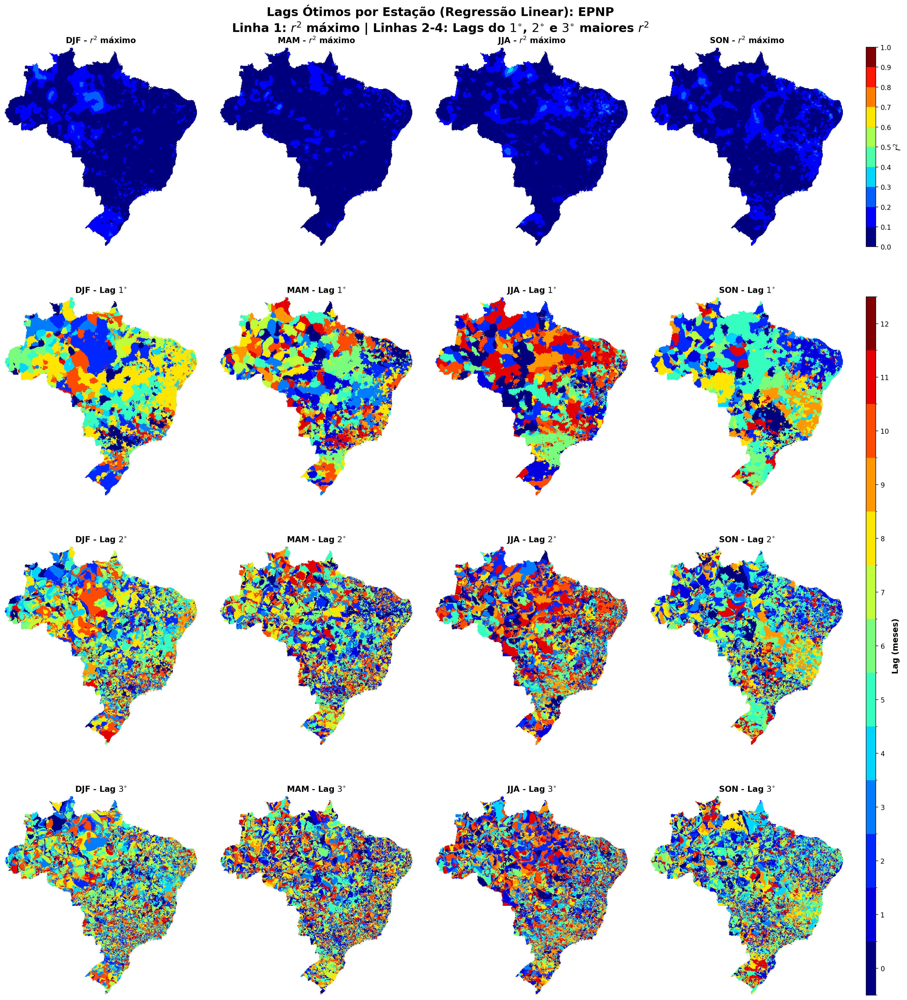

  12x4: regression_12x4_grid_EPNP.png


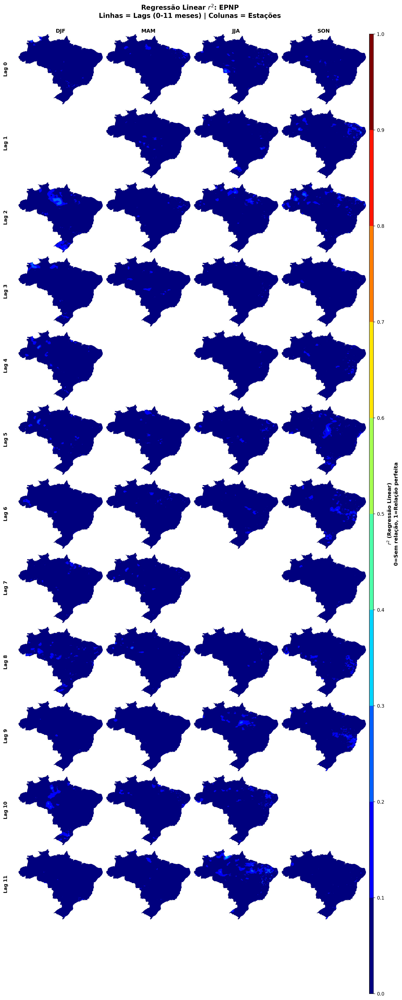


Processando: IASAS
  DJF: OK — IASAS/IASAS/IASAS_DJF_regression_brazil.nc
  MAM: OK — IASAS/IASAS/IASAS_MAM_regression_brazil.nc
  JJA: OK — IASAS/IASAS/IASAS_JJA_regression_brazil.nc
  SON: OK — IASAS/IASAS/IASAS_SON_regression_brazil.nc

Gerando plots -> ../results/regression/IASAS/plots/
  4x4:  optimal_lag_seasons_IASAS_regression.png


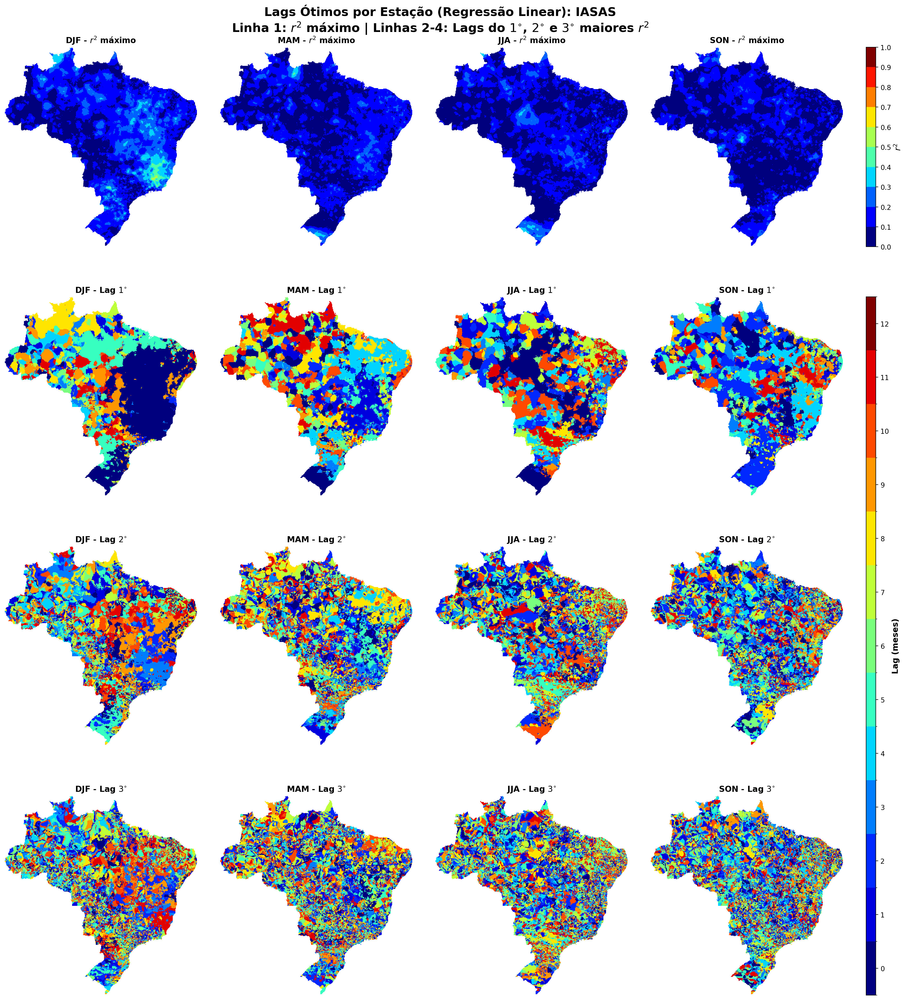

  12x4: regression_12x4_grid_IASAS.png


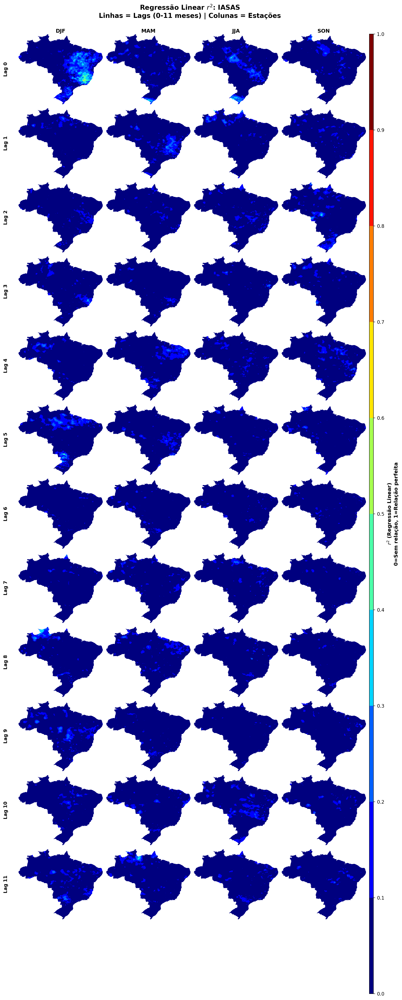


Processando: ITSMRG2
  DJF: não encontrado, pulando
  MAM: não encontrado, pulando
  JJA: não encontrado, pulando
  SON: não encontrado, pulando
  Nenhum dado completo para ITSMRG2, pulando.

Processando: MEI
  DJF: OK — MEI/MEI/MEI_DJF_regression_brazil.nc
  MAM: OK — MEI/MEI/MEI_MAM_regression_brazil.nc
  JJA: OK — MEI/MEI/MEI_JJA_regression_brazil.nc
  SON: OK — MEI/MEI/MEI_SON_regression_brazil.nc

Gerando plots -> ../results/regression/MEI/plots/
  4x4:  optimal_lag_seasons_MEI_regression.png


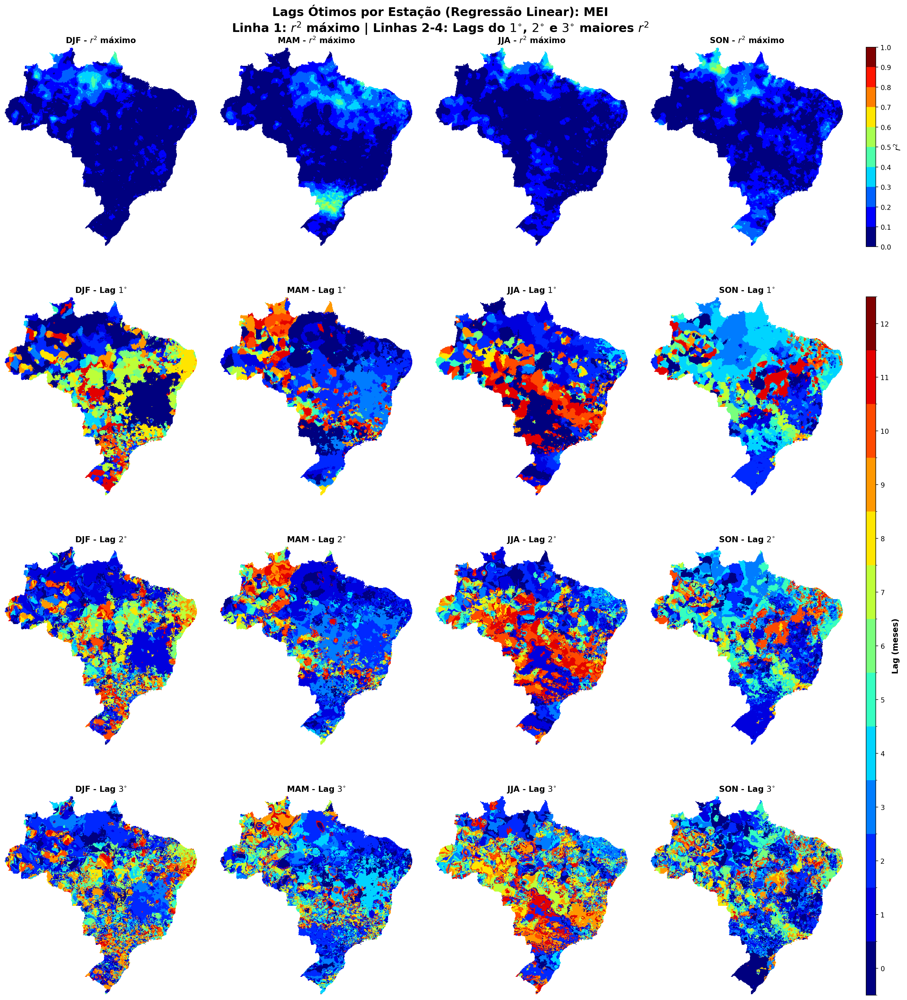

  12x4: regression_12x4_grid_MEI.png


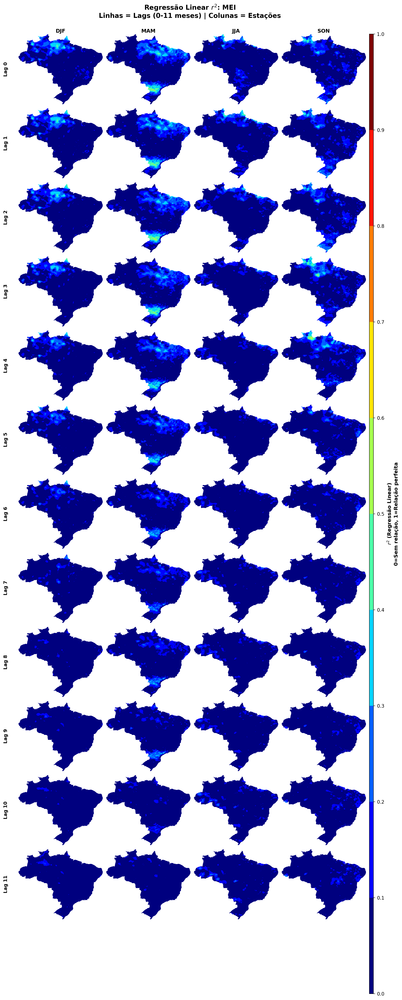


Processando: NAO
  DJF: OK — NAO/NAO/NAO_DJF_regression_brazil.nc
  MAM: OK — NAO/NAO/NAO_MAM_regression_brazil.nc
  JJA: OK — NAO/NAO/NAO_JJA_regression_brazil.nc
  SON: OK — NAO/NAO/NAO_SON_regression_brazil.nc

Gerando plots -> ../results/regression/NAO/plots/
  4x4:  optimal_lag_seasons_NAO_regression.png


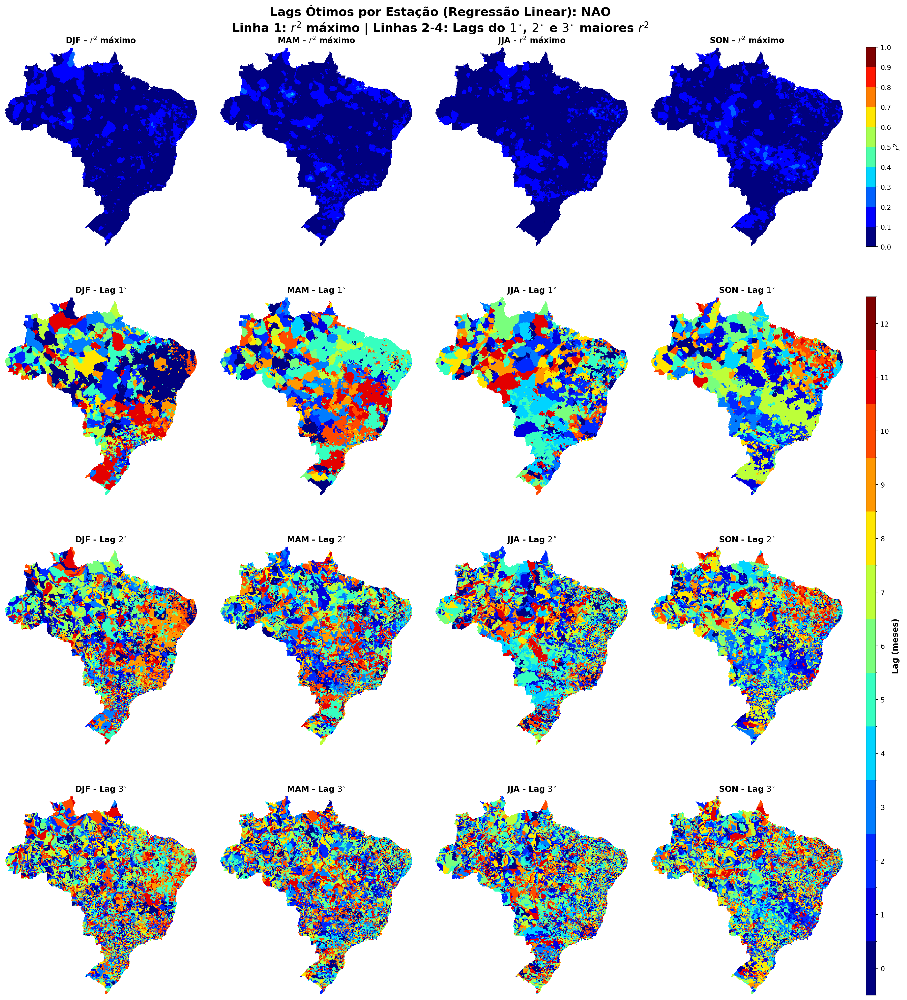

  12x4: regression_12x4_grid_NAO.png


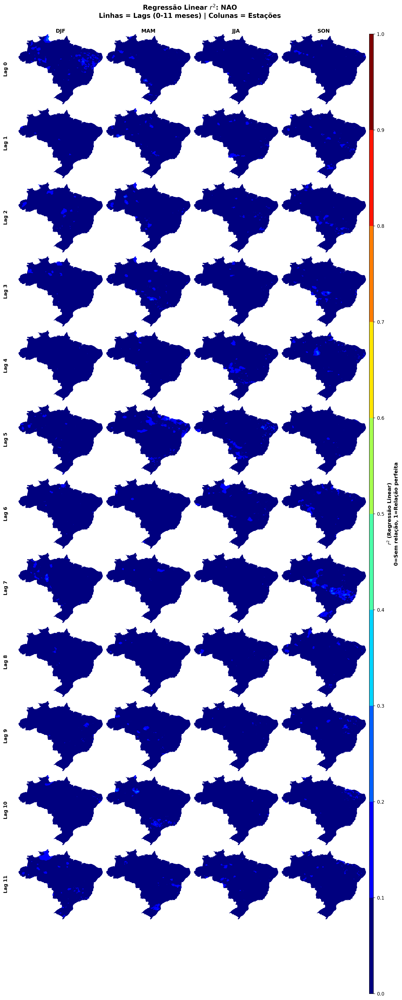


Processando: NIN03
  DJF: OK — NIN03/NIN03/NIN03_DJF_regression_brazil.nc
  MAM: OK — NIN03/NIN03/NIN03_MAM_regression_brazil.nc
  JJA: OK — NIN03/NIN03/NIN03_JJA_regression_brazil.nc
  SON: OK — NIN03/NIN03/NIN03_SON_regression_brazil.nc

Gerando plots -> ../results/regression/NIN03/plots/
  4x4:  optimal_lag_seasons_NIN03_regression.png


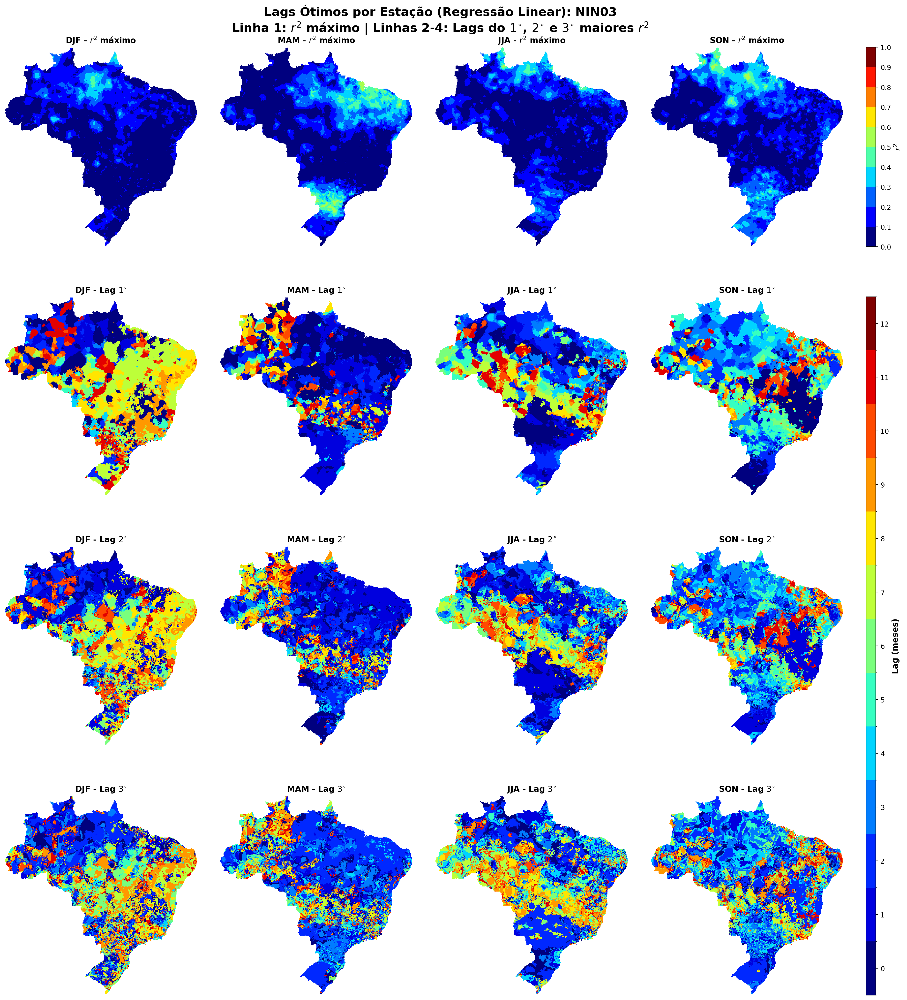

  12x4: regression_12x4_grid_NIN03.png


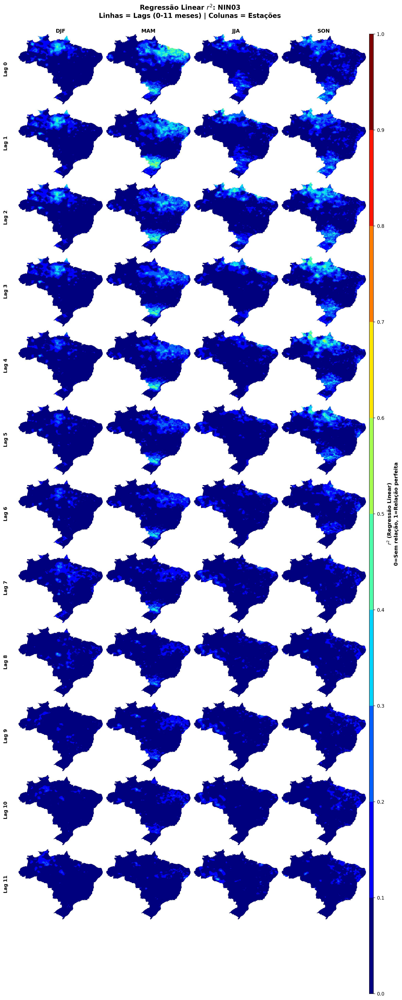


Processando: NIN034
  DJF: OK — NIN034/NIN034/NIN034_DJF_regression_brazil.nc
  MAM: OK — NIN034/NIN034/NIN034_MAM_regression_brazil.nc
  JJA: OK — NIN034/NIN034/NIN034_JJA_regression_brazil.nc
  SON: OK — NIN034/NIN034/NIN034_SON_regression_brazil.nc

Gerando plots -> ../results/regression/NIN034/plots/
  4x4:  optimal_lag_seasons_NIN034_regression.png


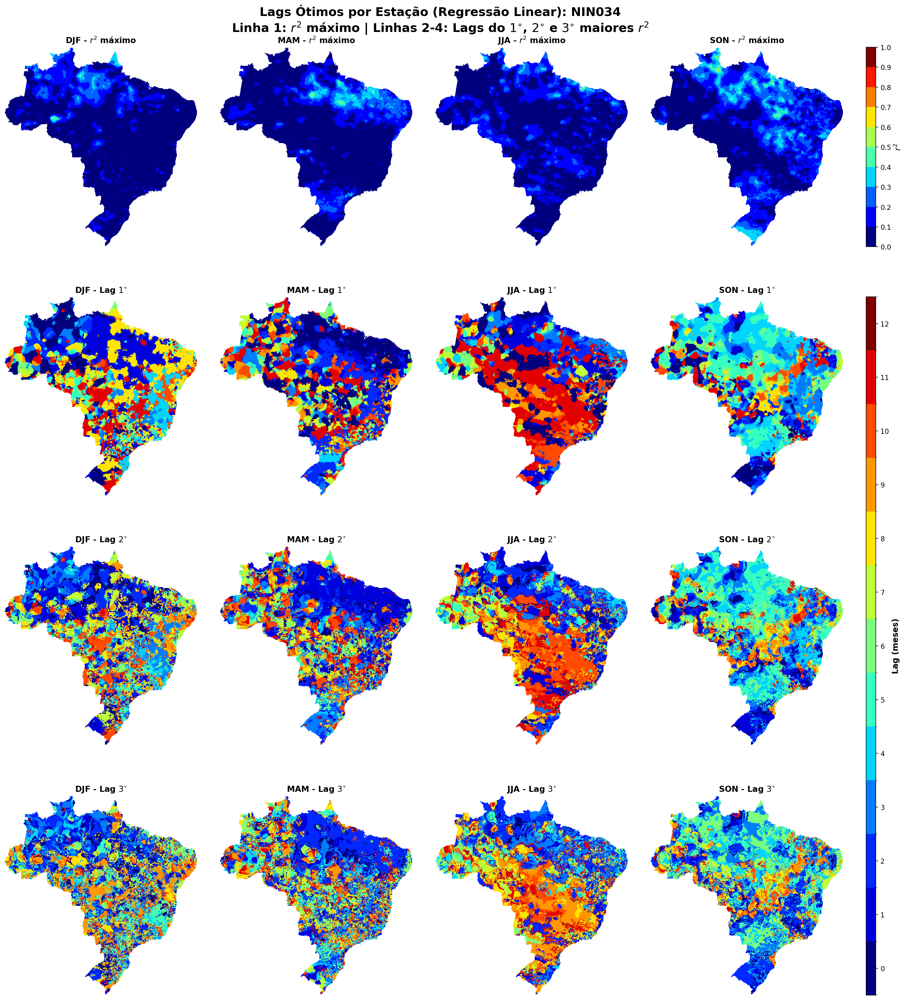

  12x4: regression_12x4_grid_NIN034.png


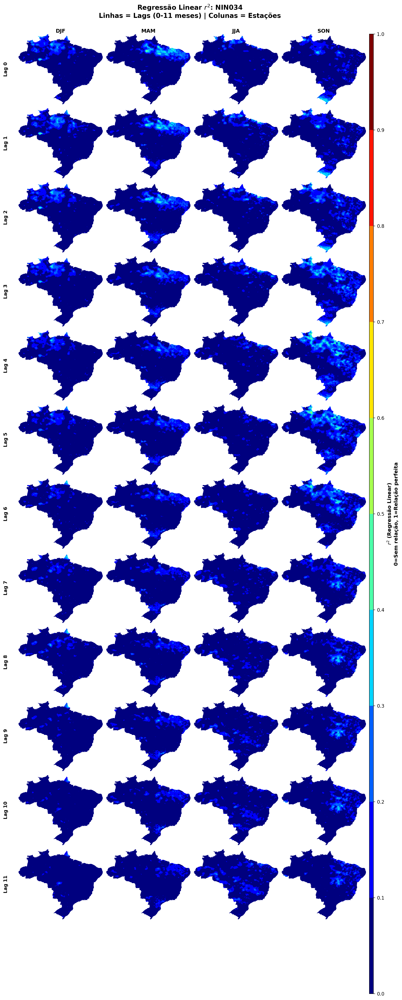


Processando: NIN04
  DJF: OK — NIN04/NIN04/NIN04_DJF_regression_brazil.nc
  MAM: OK — NIN04/NIN04/NIN04_MAM_regression_brazil.nc
  JJA: OK — NIN04/NIN04/NIN04_JJA_regression_brazil.nc
  SON: OK — NIN04/NIN04/NIN04_SON_regression_brazil.nc

Gerando plots -> ../results/regression/NIN04/plots/
  4x4:  optimal_lag_seasons_NIN04_regression.png


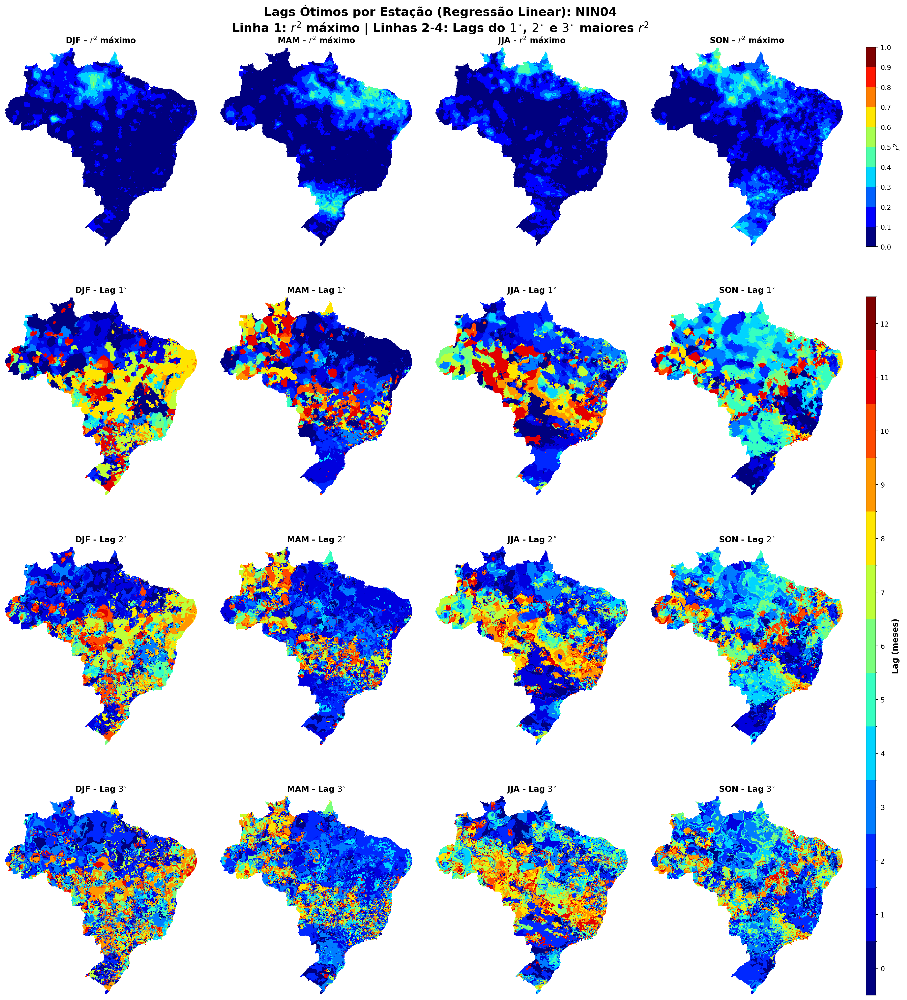

  12x4: regression_12x4_grid_NIN04.png


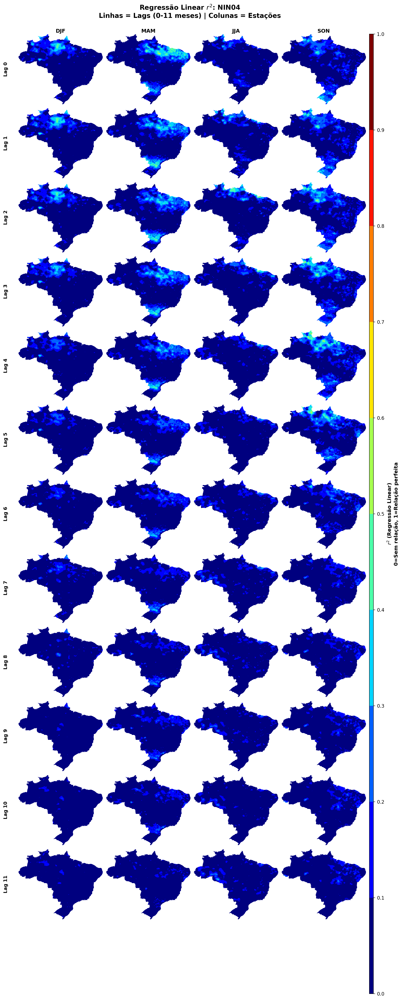


Processando: NIN12
  DJF: OK — NIN12/NIN12/NIN12_DJF_regression_brazil.nc
  MAM: não encontrado, pulando
  JJA: OK — NIN12/NIN12/NIN12_JJA_regression_brazil.nc
  SON: OK — NIN12/NIN12/NIN12_SON_regression_brazil.nc

Gerando plots -> ../results/regression/NIN12/plots/
  4x4:  optimal_lag_seasons_NIN12_regression.png


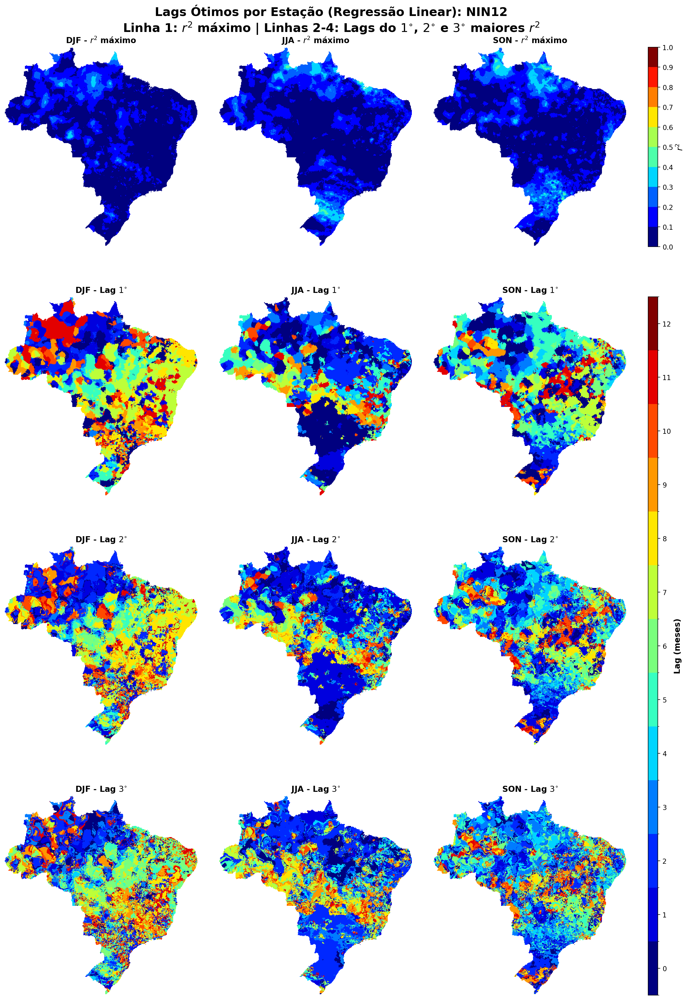

  12x4: regression_12x4_grid_NIN12.png


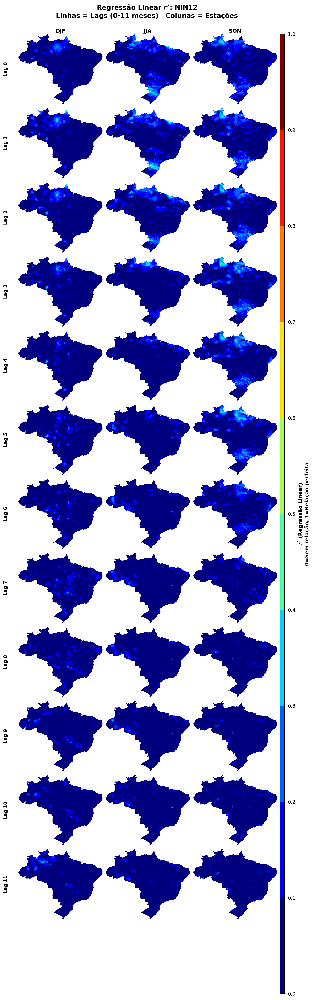


Processando: ONI
  DJF: OK — ONI/ONI/ONI_DJF_regression_brazil.nc
  MAM: OK — ONI/ONI/ONI_MAM_regression_brazil.nc
  JJA: OK — ONI/ONI/ONI_JJA_regression_brazil.nc
  SON: OK — ONI/ONI/ONI_SON_regression_brazil.nc

Gerando plots -> ../results/regression/ONI/plots/
  4x4:  optimal_lag_seasons_ONI_regression.png


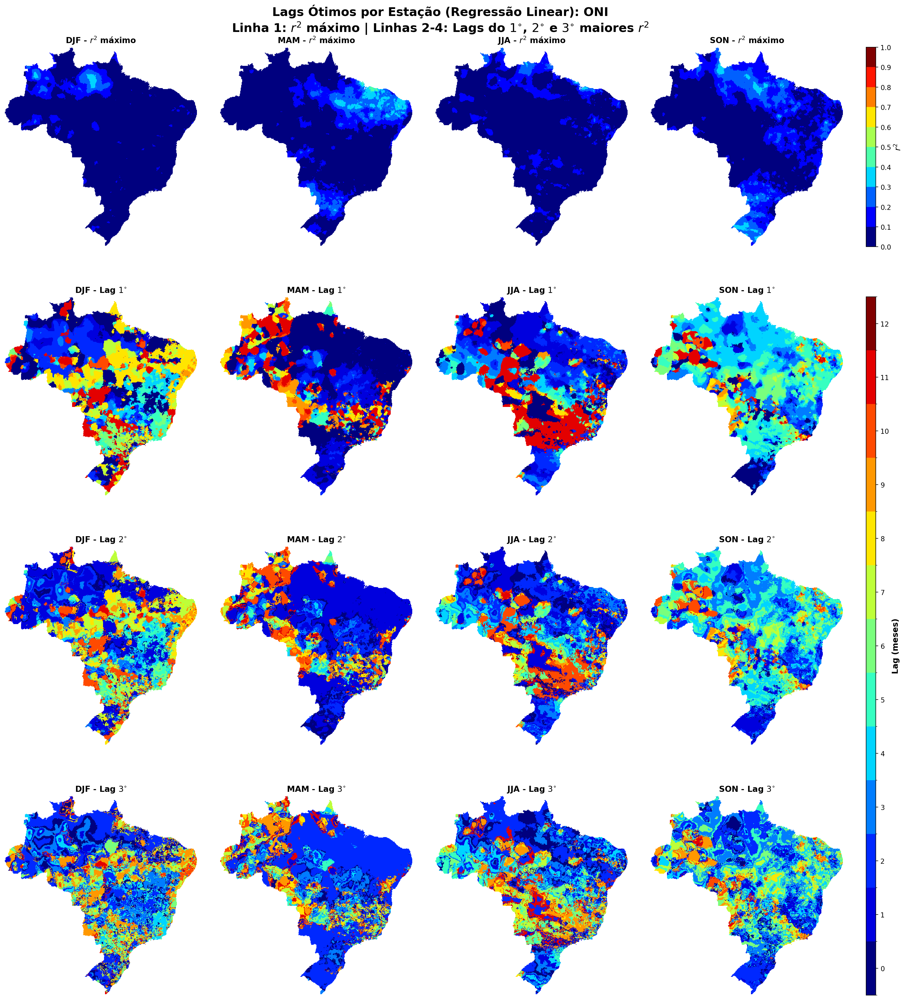

  12x4: regression_12x4_grid_ONI.png


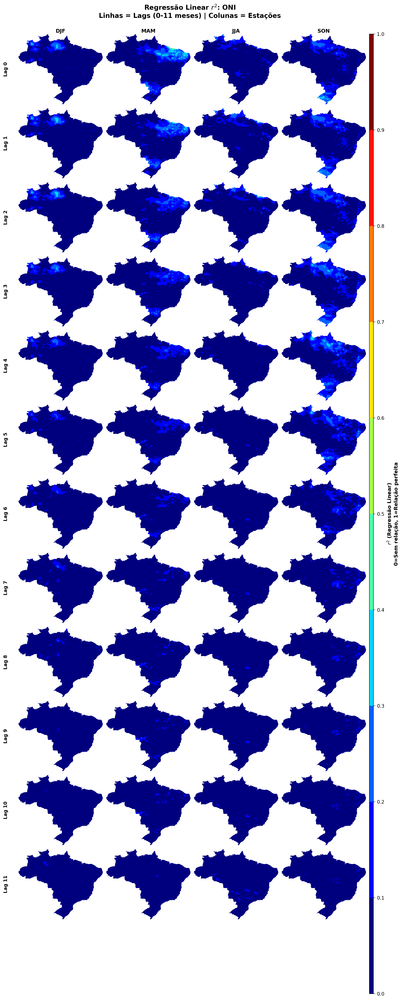


Processando: PDO
  DJF: OK — PDO/PDO/PDO_DJF_regression_brazil.nc
  MAM: OK — PDO/PDO/PDO_MAM_regression_brazil.nc
  JJA: OK — PDO/PDO/PDO_JJA_regression_brazil.nc
  SON: OK — PDO/PDO/PDO_SON_regression_brazil.nc

Gerando plots -> ../results/regression/PDO/plots/
  4x4:  optimal_lag_seasons_PDO_regression.png


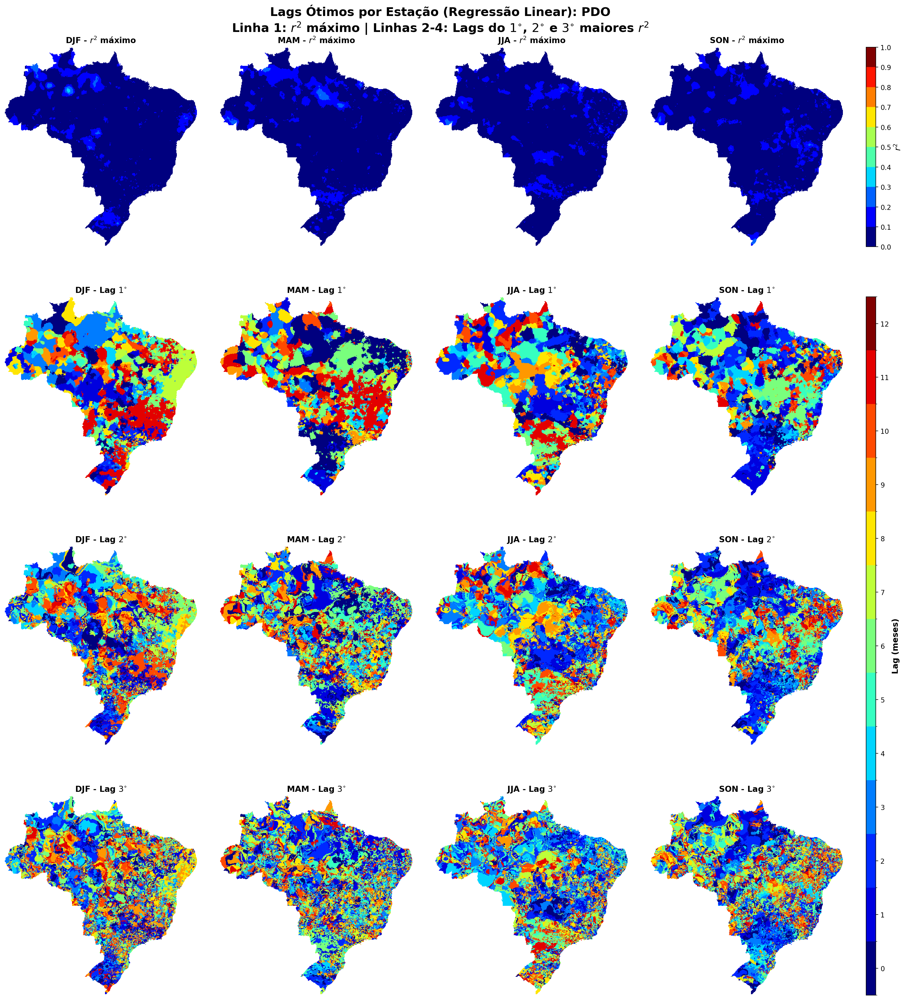

  12x4: regression_12x4_grid_PDO.png


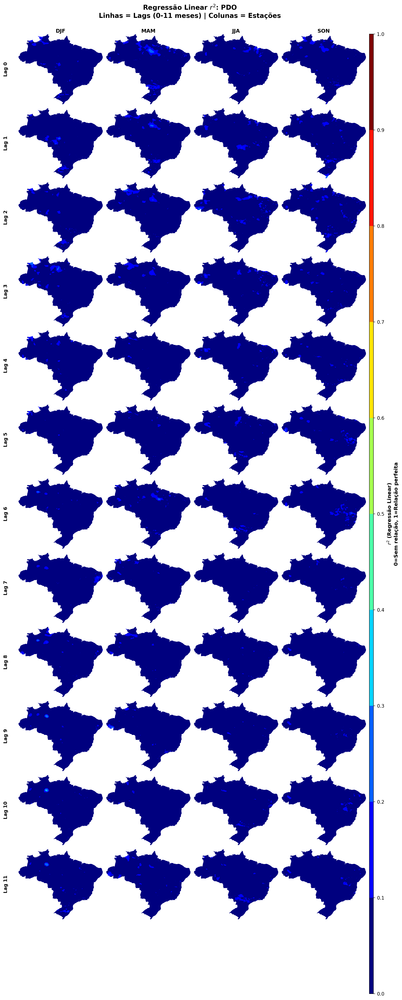


Processando: PNA
  DJF: OK — PNA/PNA/PNA_DJF_regression_brazil.nc
  MAM: OK — PNA/PNA/PNA_MAM_regression_brazil.nc
  JJA: OK — PNA/PNA/PNA_JJA_regression_brazil.nc
  SON: OK — PNA/PNA/PNA_SON_regression_brazil.nc

Gerando plots -> ../results/regression/PNA/plots/
  4x4:  optimal_lag_seasons_PNA_regression.png


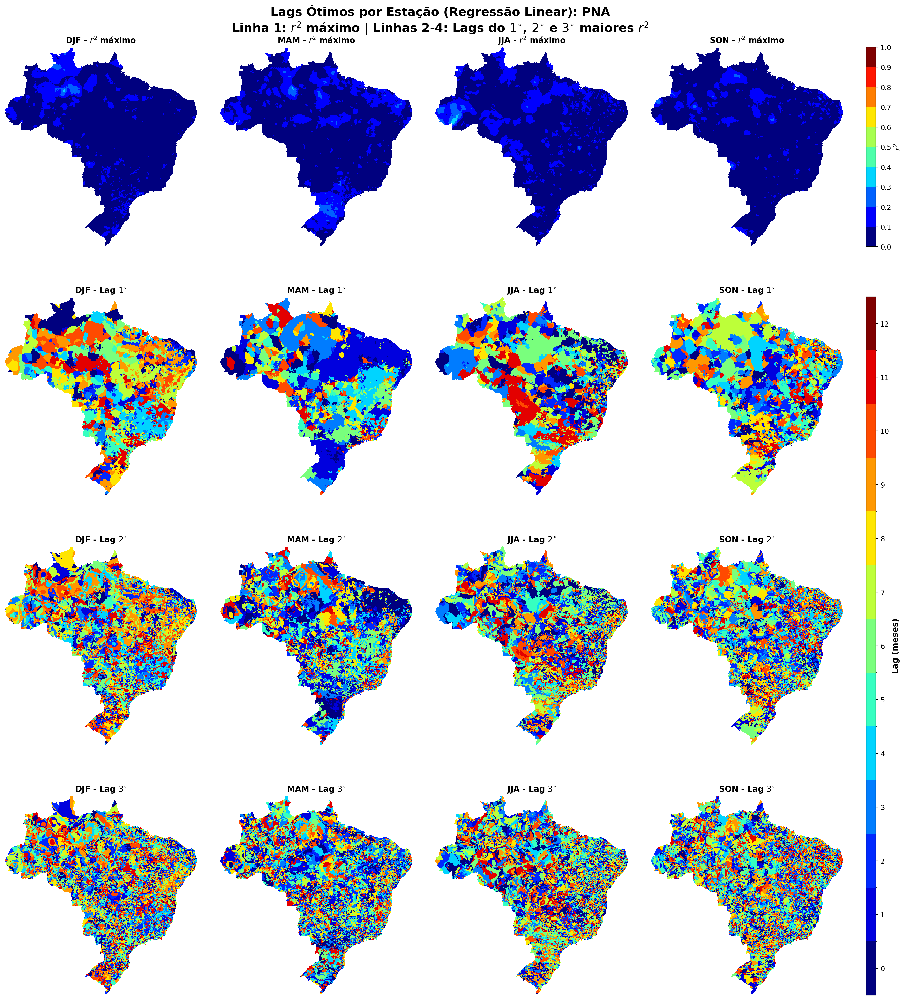

  12x4: regression_12x4_grid_PNA.png


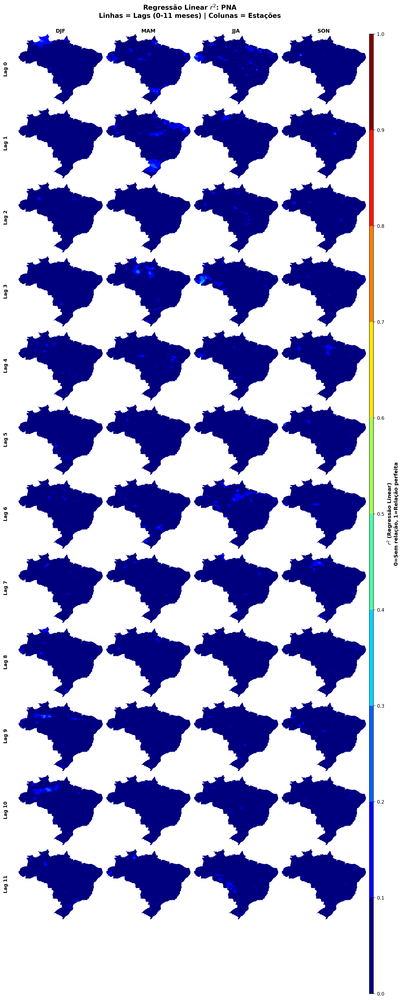


Processando: QBO
  DJF: OK — QBO/QBO/QBO_DJF_regression_brazil.nc
  MAM: OK — QBO/QBO/QBO_MAM_regression_brazil.nc
  JJA: OK — QBO/QBO/QBO_JJA_regression_brazil.nc
  SON: não encontrado, pulando

Gerando plots -> ../results/regression/QBO/plots/
  4x4:  optimal_lag_seasons_QBO_regression.png


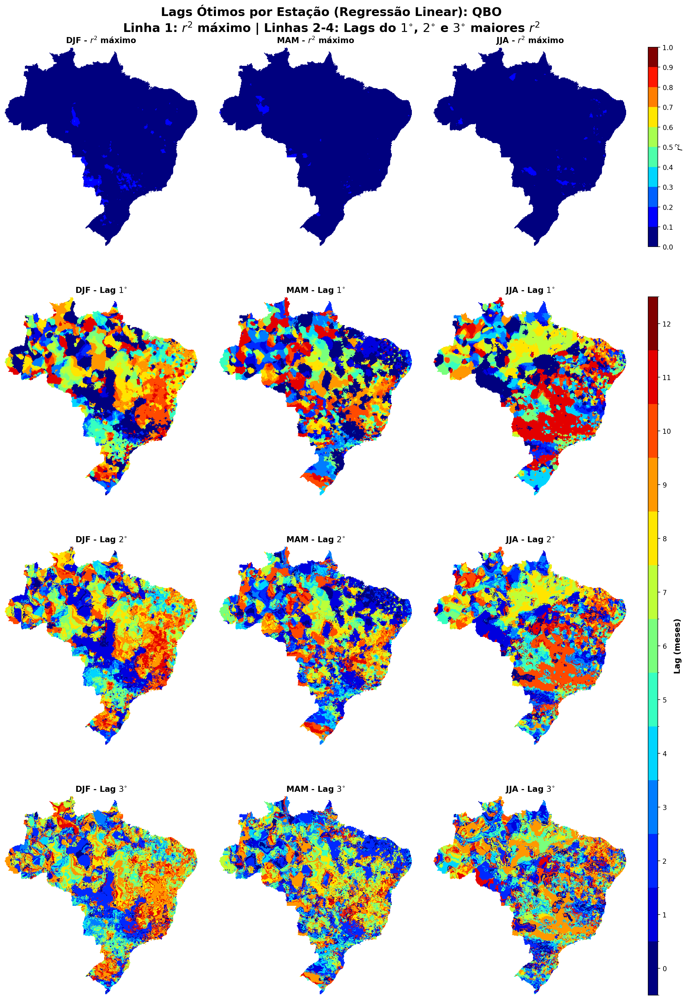

  12x4: regression_12x4_grid_QBO.png


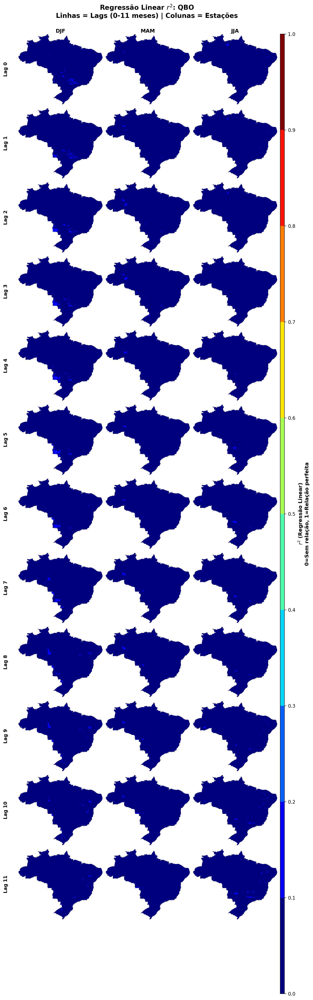


Processando: SAODI
  DJF: OK — SAODI/SAODI/SAODI_DJF_regression_brazil.nc
  MAM: OK — SAODI/SAODI/SAODI_MAM_regression_brazil.nc
  JJA: OK — SAODI/SAODI/SAODI_JJA_regression_brazil.nc
  SON: OK — SAODI/SAODI/SAODI_SON_regression_brazil.nc

Gerando plots -> ../results/regression/SAODI/plots/
  4x4:  optimal_lag_seasons_SAODI_regression.png


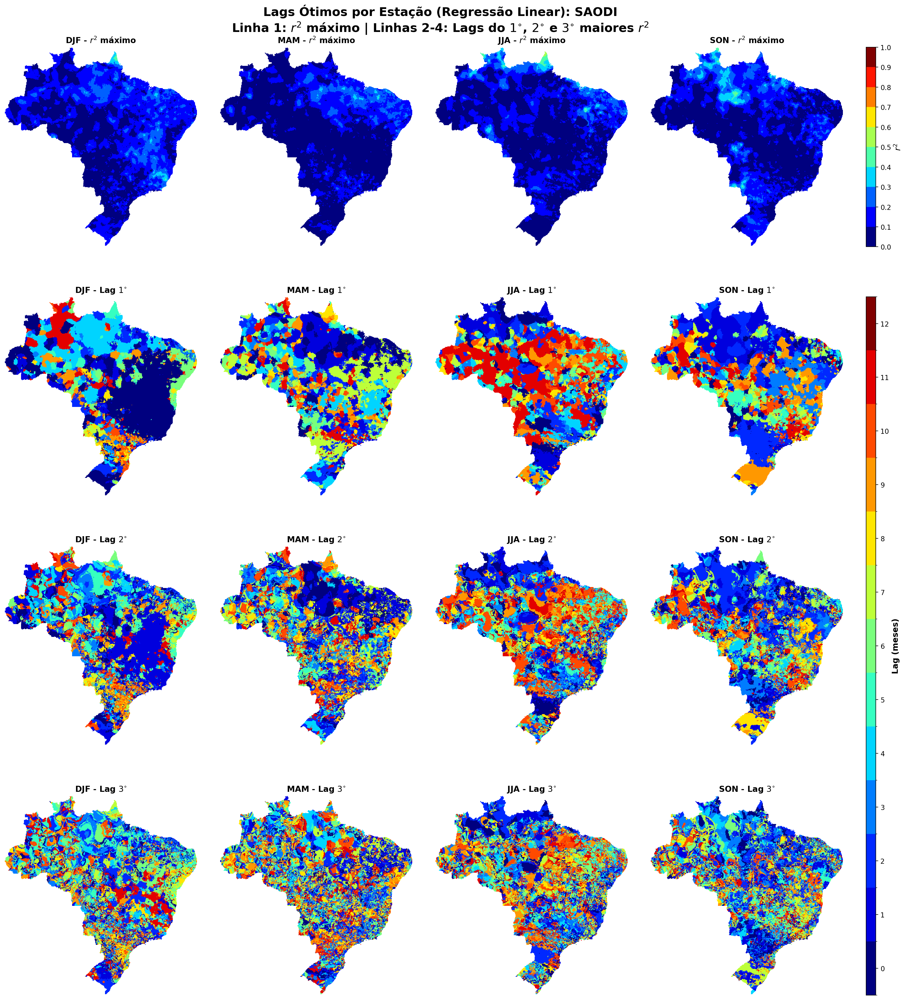

  12x4: regression_12x4_grid_SAODI.png


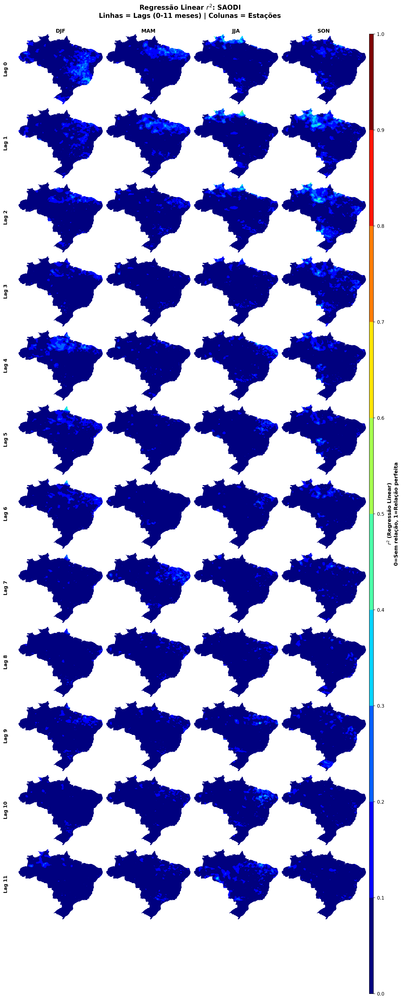


Processando: SASDI
  DJF: OK — SASDI/SASDI/SASDI_DJF_regression_brazil.nc
  MAM: incompleto (6/12 lags), pulando
  JJA: OK — SASDI/SASDI/SASDI_JJA_regression_brazil.nc
  SON: OK — SASDI/SASDI/SASDI_SON_regression_brazil.nc

Gerando plots -> ../results/regression/SASDI/plots/
  4x4:  optimal_lag_seasons_SASDI_regression.png


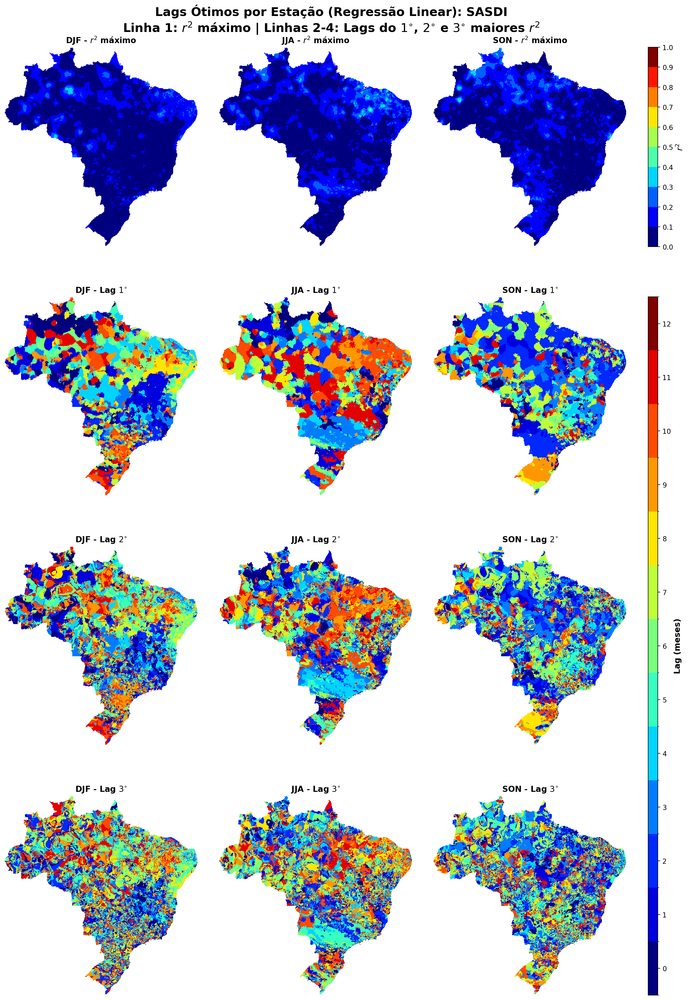

  12x4: regression_12x4_grid_SASDI.png


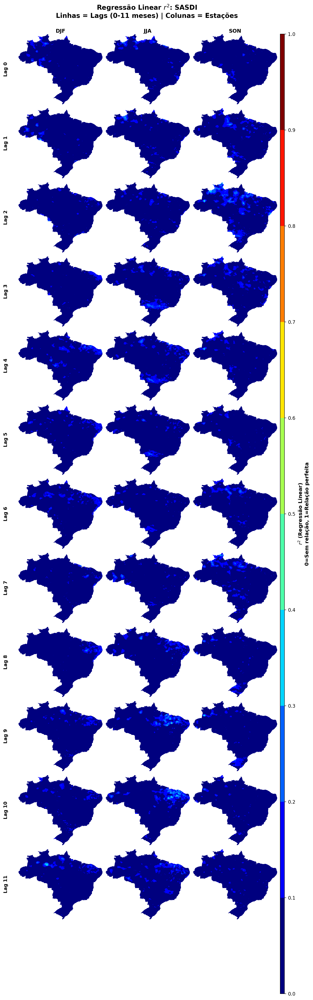


Processando: SIOD
  DJF: OK — SIOD/SIOD/SIOD_DJF_regression_brazil.nc
  MAM: OK — SIOD/SIOD/SIOD_MAM_regression_brazil.nc
  JJA: OK — SIOD/SIOD/SIOD_JJA_regression_brazil.nc
  SON: OK — SIOD/SIOD/SIOD_SON_regression_brazil.nc

Gerando plots -> ../results/regression/SIOD/plots/
  4x4:  optimal_lag_seasons_SIOD_regression.png


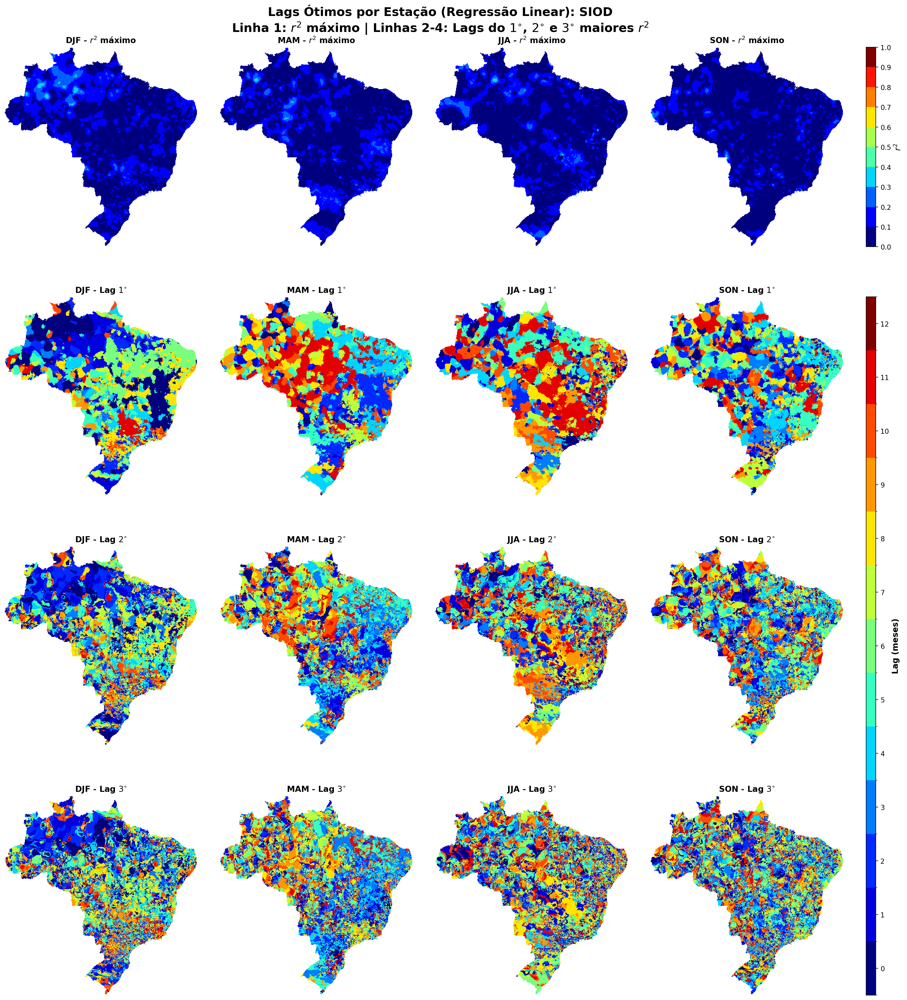

  12x4: regression_12x4_grid_SIOD.png


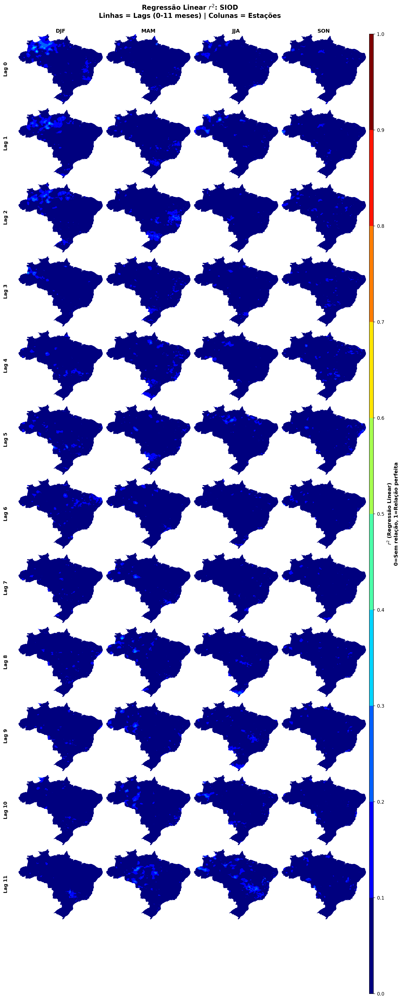


Processando: SOI
  DJF: OK — SOI/SOI/SOI_DJF_regression_brazil.nc
  MAM: OK — SOI/SOI/SOI_MAM_regression_brazil.nc
  JJA: OK — SOI/SOI/SOI_JJA_regression_brazil.nc
  SON: OK — SOI/SOI/SOI_SON_regression_brazil.nc

Gerando plots -> ../results/regression/SOI/plots/
  4x4:  optimal_lag_seasons_SOI_regression.png


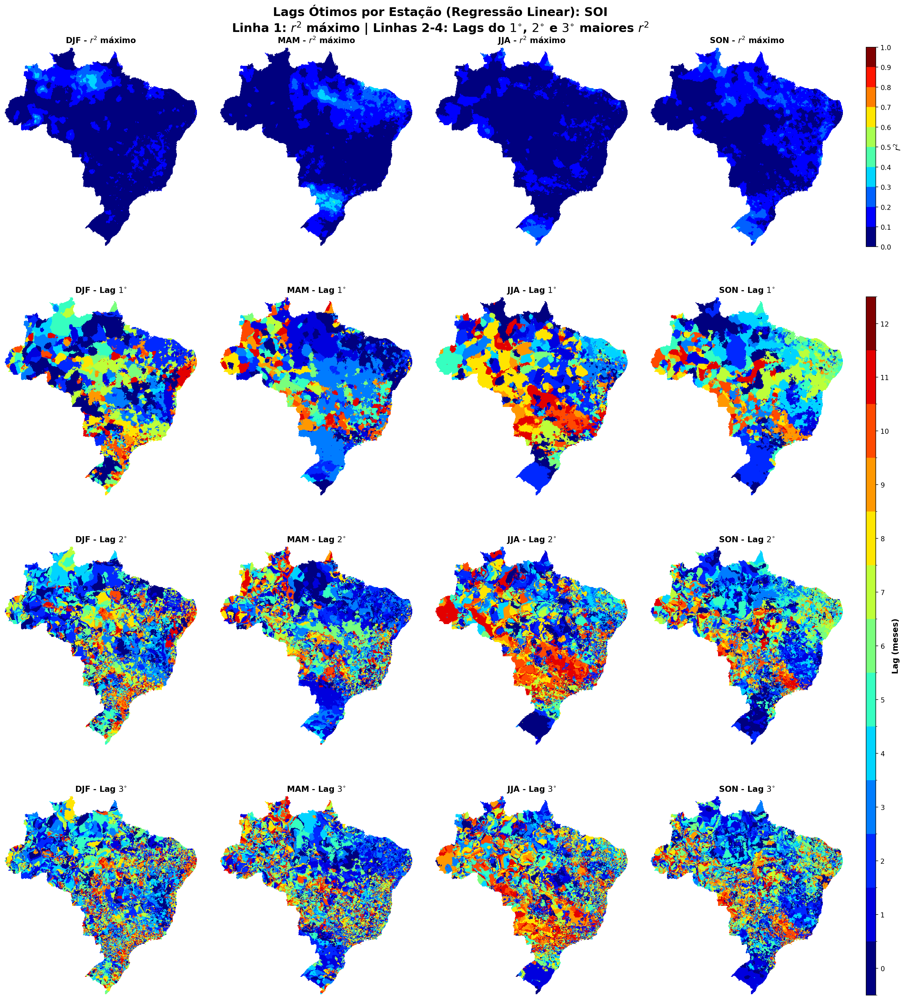

  12x4: regression_12x4_grid_SOI.png


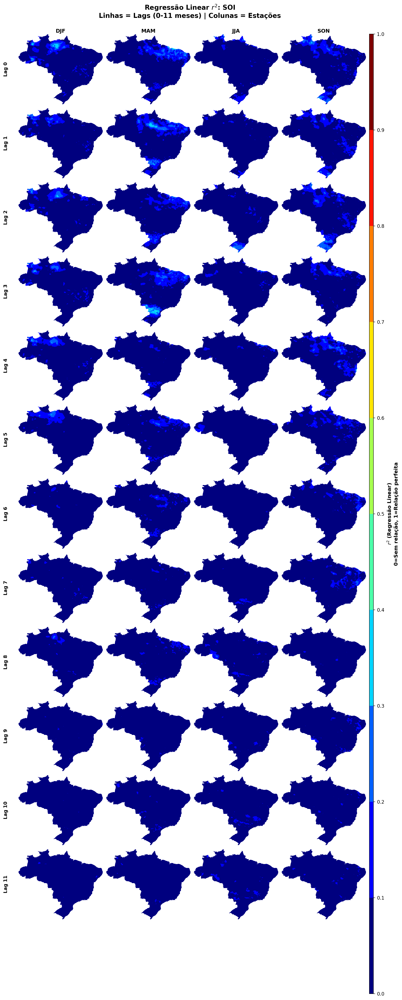


Processando: TNA
  DJF: OK — TNA/TNA/TNA_DJF_regression_brazil.nc
  MAM: OK — TNA/TNA/TNA_MAM_regression_brazil.nc
  JJA: OK — TNA/TNA/TNA_JJA_regression_brazil.nc
  SON: OK — TNA/TNA/TNA_SON_regression_brazil.nc

Gerando plots -> ../results/regression/TNA/plots/
  4x4:  optimal_lag_seasons_TNA_regression.png


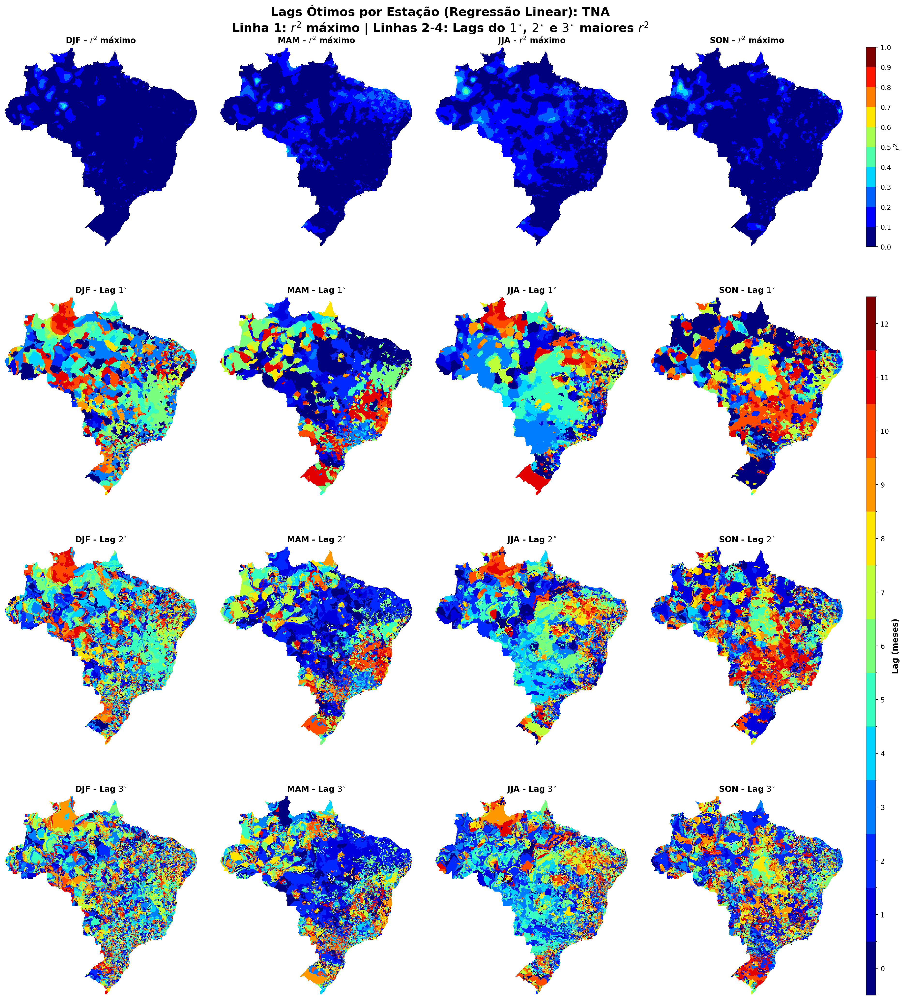

  12x4: regression_12x4_grid_TNA.png


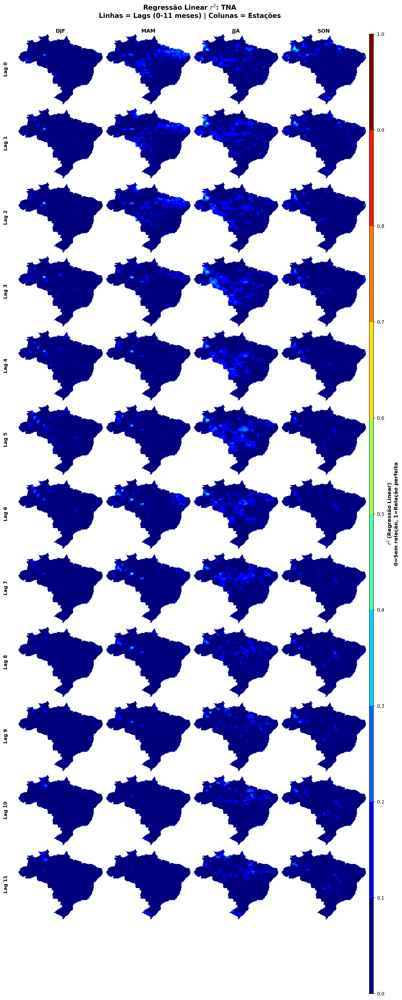


Processando: TSA
  DJF: OK — TSA/TSA/TSA_DJF_regression_brazil.nc
  MAM: OK — TSA/TSA/TSA_MAM_regression_brazil.nc
  JJA: não encontrado, pulando
  SON: OK — TSA/TSA/TSA_SON_regression_brazil.nc

Gerando plots -> ../results/regression/TSA/plots/
  4x4:  optimal_lag_seasons_TSA_regression.png


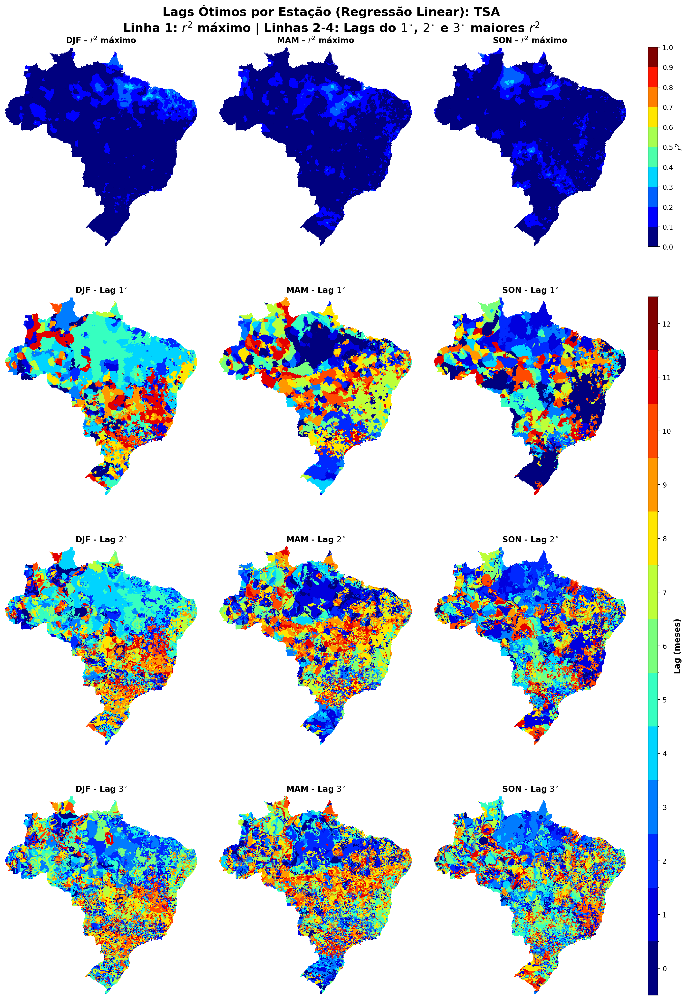

  12x4: regression_12x4_grid_TSA.png


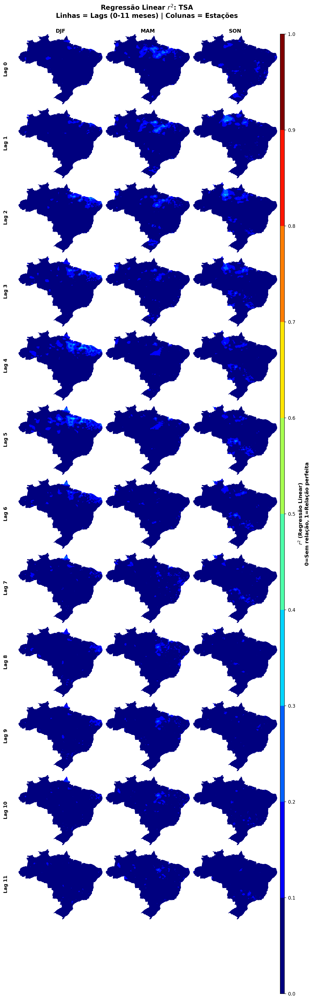


Processando: WP
  DJF: OK — WP/WP/WP_DJF_regression_brazil.nc
  MAM: OK — WP/WP/WP_MAM_regression_brazil.nc
  JJA: OK — WP/WP/WP_JJA_regression_brazil.nc
  SON: OK — WP/WP/WP_SON_regression_brazil.nc

Gerando plots -> ../results/regression/WP/plots/
  4x4:  optimal_lag_seasons_WP_regression.png


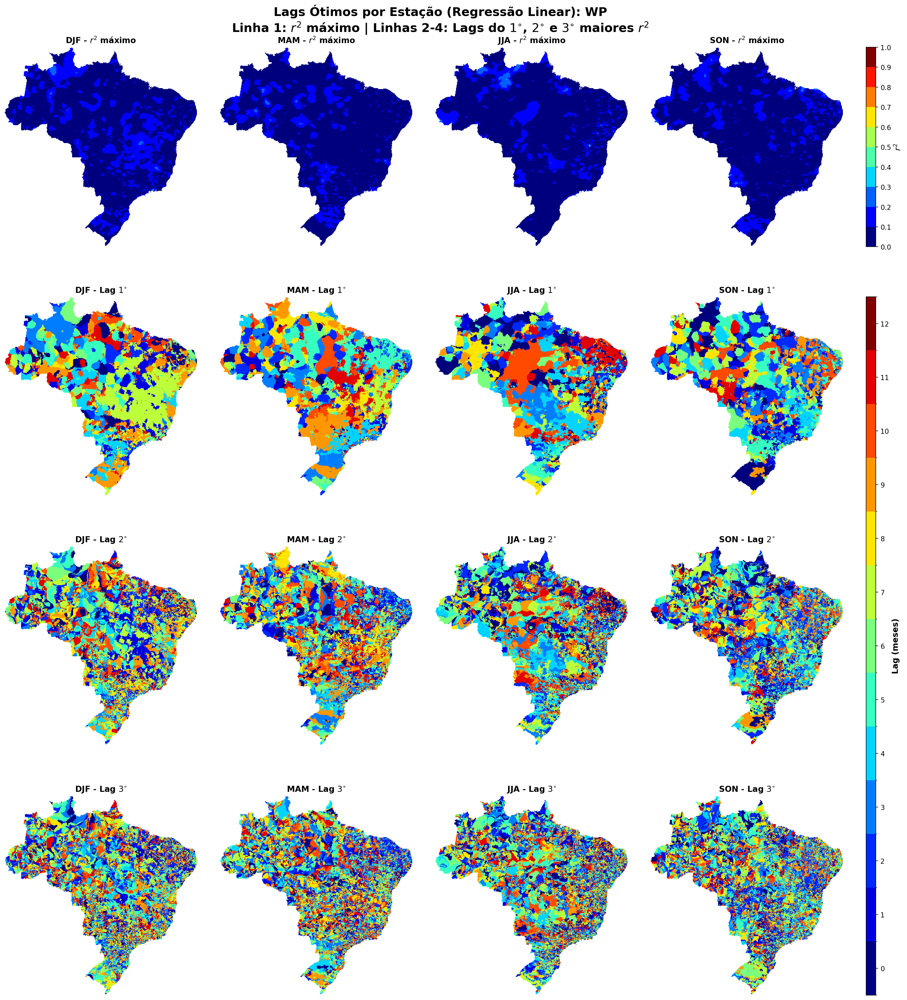

  12x4: regression_12x4_grid_WP.png


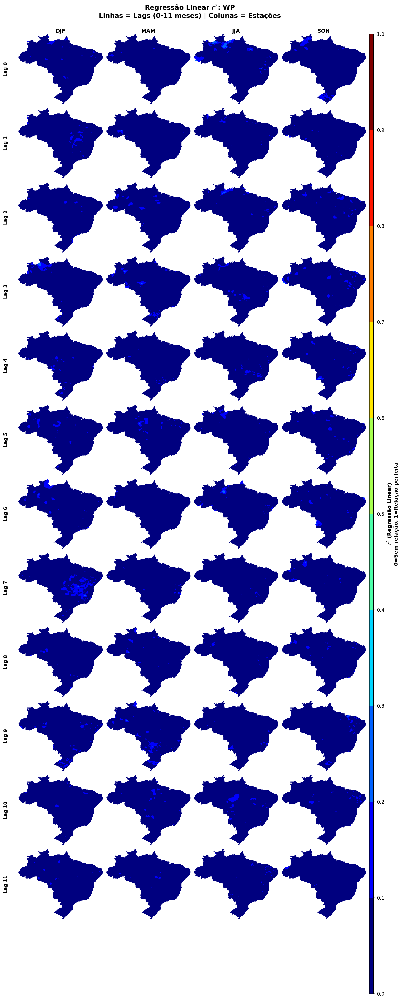


Todos os índices processados.


In [3]:
from IPython.display import Image, display

SEASONS = ["DJF", "MAM", "JJA", "SON"]
BASE_DIR = Path("../results/regression")
N_LAGS_EXPECTED = 12


def find_season_file(mov_dir, mov_index, season):
    matches = list(mov_dir.rglob(f"{mov_index}_{season}_regression_brazil.nc"))
    return matches[0] if matches else None


# Descobrir índices disponíveis
mov_indices = sorted([d.name for d in BASE_DIR.iterdir() if d.is_dir()])

print(f"Índices disponíveis: {len(mov_indices)}")
for m in mov_indices:
    nc_count = len(list((BASE_DIR / m).rglob("*.nc")))
    print(f"  {m}: {nc_count} arquivo(s) .nc")
print()

for mov_index in mov_indices:
    results_dir = BASE_DIR / mov_index
    print(f"\n{'='*50}")
    print(f"Processando: {mov_index}")
    print('='*50)

    all_data, seasons_loaded = [], []
    lats = lons = None

    for season in SEASONS:
        nc_file = find_season_file(results_dir, mov_index, season)
        if nc_file is None:
            print(f"  {season}: não encontrado, pulando")
            continue
        try:
            ds = xr.open_dataset(nc_file)
            lag_vars = sorted(
                [v for v in ds.data_vars if v.startswith("r2_lag")],
                key=lambda x: int(x.replace("r2_lag", ""))
            )
            if len(lag_vars) < N_LAGS_EXPECTED:
                print(f"  {season}: incompleto ({len(lag_vars)}/{N_LAGS_EXPECTED} lags), pulando")
                ds.close()
                continue
            r2_list = [ds[v].values for v in lag_vars]
            all_data.append(np.stack(r2_list, axis=0))
            seasons_loaded.append(season)
            if lats is None:
                lats = ds.latitude.values
                lons = ds.longitude.values
            ds.close()
            print(f"  {season}: OK — {nc_file.relative_to(BASE_DIR)}")
        except OSError as e:
            print(f"  {season}: corrompido, pulando ({nc_file.name})")
            continue

    if not all_data:
        print(f"  Nenhum dado completo para {mov_index}, pulando.")
        continue

    combined_r2 = np.stack(all_data, axis=0)[np.newaxis, :, :, :, :]
    ds_combined = xr.Dataset(
        {'regression_r2': (
            ['mov', 'season', 'lag', 'latitude', 'longitude'], combined_r2
        )},
        coords={
            'mov': [mov_index],
            'season': seasons_loaded,
            'lag': list(range(N_LAGS_EXPECTED)),
            'latitude': lats,
            'longitude': lons,
        }
    )

    output_dir = results_dir / "plots"
    output_dir.mkdir(exist_ok=True)
    print(f"\nGerando plots -> {output_dir}/")

    out_4x4 = plot_4x4_optimal_lags_r2(
        ds_combined, mov_index, output_dir, seasons_loaded
    )
    out_12x4 = plot_12x4_all_lags_r2(
        ds_combined, mov_index, output_dir, seasons_loaded
    )

    if out_4x4:
        print(f"  4x4:  {out_4x4.name}")
        display(Image(filename=str(out_4x4)))
    if out_12x4:
        print(f"  12x4: {out_12x4.name}")
        display(Image(filename=str(out_12x4)))

print("\n" + "="*50)
print("Todos os índices processados.")
